# 01. 설문 기반 문화 성향 군집 분석

**목적** — 설문 응답으로 개인의 문화 성향을 분류해 추천 엔진의 입력으로 사용

| 항목 | 내용 |
|---|---|
| 데이터 | 자체 설문 181명 (청년 19~34세 154명) — 원본은 개인정보 보호를 위해 비공개 |
| 입력 피처 | Q9 · Q14 · Q15 · Q16 · Q19(단일 선택, 원핫 13개) + Q20(복수 선택 9개) = 22개 |
| 방법 | K-means 군집 탐색 → 군집 구조 검증 → 2문항(Q14·Q16) 규칙 기반 3유형으로 단순화 → 유형별 Q20 선호 차이 검정 |
| 산출물 | 문화 성향 3유형(집콕힐링형 · 야외활동형 · 문화예술형), 분류기(`src/culture_classifier.py`) |

In [1]:
from google.colab import drive
drive.mount('/content/drive')

%cd "/content/drive/MyDrive/데이터분석_포트폴리오/youth-culture-recommendation/notebooks"
!ls ../data | head
!pip install -q -r ../requirements.txt
!apt-get -qq install fonts-nanum > /dev/null

import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

Mounted at /content/drive
/content/drive/MyDrive/데이터분석_포트폴리오/youth-culture-recommendation/notebooks
raw
README.md
recommend_master_db.csv
survey_google.xlsx
survey_modu.xlsx


In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")

# 한글 폰트 (Windows: Malgun Gothic / macOS: AppleGothic)
matplotlib.rc("font", family="NanumGothic")
matplotlib.rcParams["axes.unicode_minus"] = False

DATA_DIR = "../data"      # 설문 원본 (비공개 — 저장소에 포함하지 않음)
MODEL_DIR = "../models"   # 분류 모델 저장 위치
IMG_DIR = "../images"     # 그래프 저장 위치
os.makedirs(IMG_DIR, exist_ok=True)

## 1. 데이터 전처리

In [3]:
# 설문 원본 2종 (구글폼 · 모두의 설문) 불러오기 — 첫 열(타임스탬프) 제외
df_google = pd.read_excel(f"{DATA_DIR}/survey_google.xlsx", usecols=range(1, 21))
df_modu = pd.read_excel(f"{DATA_DIR}/survey_modu.xlsx", usecols=range(1, 21))
print(df_google.shape, df_modu.shape)

(163, 20) (18, 20)


In [4]:
# 컬럼명 정제

column_mapping = {
    '1. 연령대를 선택해 주세요.': 'age_group',
    '2. 현재 거주 중인 시·도를 선택해 주세요.': 'sido',
    '3. 현재 거주 중인 시·군·구를 입력해 주세요.': 'sigungu',
    '4. 현재 가장 가까운 상황을 선택해 주세요.': 'current_status',
    '5. 최근 2주 동안, 평소 좋아하던 일에 흥미나 즐거움을 얼마나 느꼈나요?': 'q5_pleasure',
    '6. 최근 2주 동안, 기분이 가라앉거나 우울하거나 희망이 없다고 얼마나 느꼈나요?': 'q6_depression',
    '7. 주말에 아무 일정이 없을 때, 요즘 나의 기본 상태에 가장 가까운 것은?': 'q7_weekend',
    '8.  최근 한 달 동안 나의 정신적 피로도(번아웃)를 점수로 표현한다면?': 'q8_burnout',
    '9. 나의 감성과 텐션이 가장 높게 차오르는(혹은 외출하기 편한) 시간대는?': 'q9_time',
    '10.  최근 일주일간 집 밖에서 순수한 여가 목적으로 외출한 횟수는?(퇴근·등교 같은 의무 외출 제외)': 'q10_out_count',
    '10.  최근 일주일간 집 밖에서 순수한 여가 목적으로 외출한 횟수는?(출근·등교 같은 의무 외출 제외)': 'q10_out_count',
    '11. 속마음을 편하게 털어놓거나 나를 온전히 이해해 주는 사람이 주변에 얼마나 있나요?': 'q11_friends',
    '12.  지금 혼자인 것이 어떻게 느껴지나요?': 'q12_lonely',
    '13.  처음 보는 사람들이 있거나, 새로운 문화 공간에 들어가는 상황을 상상하면?': 'q13_new_space',
    '14. 문화 활동을 할 때, 어느 곳이 더 편한가요?': 'q14_place_pref',
    '15.  문화 활동 중 다른 참여자와의 소통은 어느 정도가 편한가요?': 'q15_interaction',
    '16. 지금 당장 내 눈앞에 펼쳐졌으면 하는 힐링 플레이스는?': 'q16_healing_spot',
    '17.  문화 행사 참여를 위해 심리적으로 이동 가능한 최대 거리(편도)는?': 'q17_distance',
    '18.  문화 생활 1회 참여 시 부담 없이 지불할 수 있는 예산은?': 'q18_budget',
    '19.  예술 작품을 감상하거나 여가를 즐길 때, 나의 마음을 더 움직이는 방식은?': 'q19_stimulus_type',
    '20.  스트레스가 머리끝까지 찼을 때, 내게 더 필요한 힐링의 형태는? 즐기고 싶은 문화생활은?': 'q20_preference_detail'
}

df_google = df_google.rename(columns = column_mapping)
df_modu = df_modu.rename(columns = column_mapping)

In [5]:
# 데이터 병합
df_survey = pd.concat([df_google, df_modu], axis=0, ignore_index=True)
print(f"전체 응답자: {len(df_survey)}명")

# 시군구 명칭 보정 (시군구 대신 '서울', '구'로 응답한 경우)
mask_error = (
    ((df_survey["sido"] == "서울특별시") & (df_survey["sigungu"] == "서울"))
    | ((df_survey["sido"] == "경상남도") & (df_survey["sigungu"] == "구"))
)
df_survey.loc[mask_error, "sigungu"] = "전체"

전체 응답자: 181명


In [6]:
print(df_survey['age_group'].value_counts().sort_index())
print(f"\n전체: {len(df_survey)}명")

youth_ages  = ['만 19~22세', '만 23~26세', '만 27~30세', '만 31~34세']
older_ages = ['만 35~40세', '만 41~50세', '만 51~60세', '만 61세 이상']
minor_ages  = ['만 19세 미만']

df_survey['generation'] = df_survey['age_group'].apply(
    lambda x: '청년(19~34세)' if x in youth_ages
    else ('기성세대(35세+)' if x in older_ages
    else ('미성년(19세 미만)' if x in minor_ages else '기타'))
)
print("\n[세대 분포]")
print(df_survey['generation'].value_counts())

age_group
만 19~22세     7
만 19세 미만     5
만 23~26세    25
만 27~30세    95
만 31~34세    27
만 35~40세    11
만 41~50세     8
만 51~60세     1
만 61세 이상     2
Name: count, dtype: int64

전체: 181명

[세대 분포]
generation
청년(19~34세)     154
기성세대(35세+)      22
미성년(19세 미만)      5
Name: count, dtype: int64


## 2. 전체 응답자 K-means 탐색 (181명, 초기 분석)

- 전체 응답자로 먼저 k=2~8을 탐색하고, k=3 군집 프로파일과 시각화로 초기 성향을 확인
- 여기서 저장한 K-means 분류기는 규칙 기반 분류와 비교하기 위한 용도

[원핫 인코딩] 5개 문항 -> 13개 피처
[Q20 원핫] 9개 피처
[클러스터링 입력] 총 22개 피처, 181명
k=2: 실루엣 = 0.126
k=3: 실루엣 = 0.119
k=4: 실루엣 = 0.115
k=5: 실루엣 = 0.122
k=6: 실루엣 = 0.108
k=7: 실루엣 = 0.111
k=8: 실루엣 = 0.115

[Silhouette 기준 최적 k = 2]
{2: np.float64(0.126), 3: np.float64(0.119), 4: np.float64(0.115), 5: np.float64(0.122), 6: np.float64(0.108), 7: np.float64(0.111), 8: np.float64(0.115)}


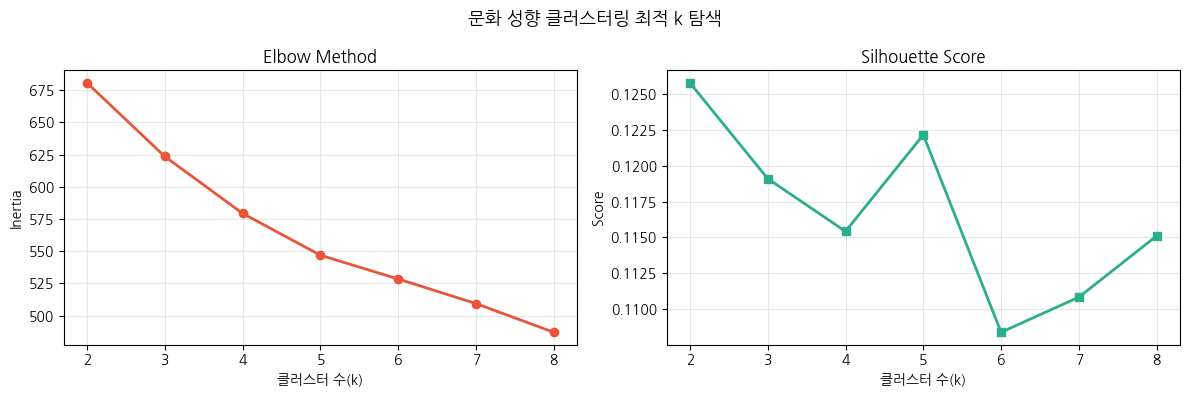

In [7]:
culture_cols = [
    'q9_time',           # 선호 시간대
    'q14_place_pref',    # 온/오프
    'q15_interaction',   # 상호작용
    'q16_healing_spot',  # 힐링 장소
    'q19_stimulus_type'  # 언어/감각 자극
]

ohe = OneHotEncoder(sparse_output = False, handle_unknown = 'ignore')
X_ohe = ohe.fit_transform(df_survey[culture_cols])
print(f"[원핫 인코딩] {len(culture_cols)}개 문항 -> {X_ohe.shape[1]}개 피처")

# q20 다중 응답 원핫
q20_map = {
    'q20_craft':'손으로 직접 만들고 발산하기 (도예·드로잉·DIY 공방)',
    'q20_concert':'가만히 앉아 눈과 귀를 감각으로 채워내기 (콘서트·뮤지컬·전시회)',
    'q20_outdoor':'탁 트인 야외에서 맑은 공기 마시며 재충전하기 (도시공원·캠핑장·수목원)',
    'q20_cafe':'조용한 실내 공간에서 나홀로 차분하게 머물기 (독립서점·북카페·도서관)',
    'q20_heritage':'옛 자취를 따라 걸으며 평화롭게 산책하고 체험하기 (고궁·유적지·전통문화 체험)',
    'q20_sport':'땀을 흠뻑 흘리며 몸의 에너지를 폭발시키기 (자전거·러닝·스포츠 액티비티)',
    'q20_fun':'가볍고 신나게 놀면서 스트레스 날려버리기 (오락실·볼링·방탈출)',
    'q20_modern':'새롭고 낯선 시각적 자극으로 뇌를 깨우기 (현대미술 전시·독립영화)',
    'q20_classic':'익숙하고 아름다운 예술로 마음을 다독이기 (클래식 공연·풍경화 전시)'
}

for col, keyword in q20_map.items():
    df_survey[col] = df_survey['q20_preference_detail'].str.contains(keyword, na=False, regex=False).astype(int)

q20_cols = list(q20_map.keys())
X_q20 = df_survey[q20_cols].values
print(f"[Q20 원핫] {X_q20.shape[1]}개 피처")

X_culture = np.hstack([X_ohe, X_q20])
print(f"[클러스터링 입력] 총 {X_culture.shape[1]}개 피처, {X_culture.shape[0]}명")

# 최적의 k 탐색
inertias, silhouettes = [], []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters = k, random_state = 42, n_init = 10)
    labels = km.fit_predict(X_culture)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_culture, labels))
    print(f"k={k}: 실루엣 = {silhouette_score(X_culture, labels):.3f}")

best_k_auto = list(k_range)[silhouettes.index(max(silhouettes))]
print(f"\n[Silhouette 기준 최적 k = {best_k_auto}]")
print({k:round(s, 3) for k, s in zip(k_range, silhouettes)})

# k 탐색 그래프
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_range), inertias, 'o-', color='#e8553a', linewidth=2)
axes[0].set_title('Elbow Method', fontsize=12, fontweight='bold')
axes[0].set_xlabel('클러스터 수(k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(alpha=0.3)

axes[1].plot(list(k_range), silhouettes, 's-', color='#2bae8e', linewidth=2)
axes[1].set_title('Silhouette Score', fontsize=12, fontweight='bold')
axes[1].set_xlabel('클러스터 수(k)')
axes[1].set_ylabel('Score')
axes[1].grid(alpha=0.3)

plt.suptitle('문화 성향 클러스터링 최적 k 탐색', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/culture_optimal_k.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Q5+Q6 = PHQ-2 (우울 선별 척도) — 군집 결과 해석을 위한 사후 확인용
# 응답 척도: 전혀 없다 < 며칠 동안 < 7일 이상 < 거의 매일 (0~3점, 합계 0~6점)

phq_order = [['전혀 없다', '며칠 동안 느꼈다', '7일 이상 느꼈다', '거의 매일 느꼈다']]

oe = OrdinalEncoder(categories=phq_order *2)
phq_encoded = oe.fit_transform(df_survey[['q5_pleasure', 'q6_depression']])
df_survey['phq2'] = phq_encoded[:,0] + phq_encoded[:, 1] # 0~6점

# PHQ-2 위험 분류 (사후 해석용)
df_survey['phq2_risk'] = df_survey['phq2'].apply(lambda x: '임상위험' if x >= 3 else '비위험')
print('\n[PHQ-2 위험군 분포]')
print(df_survey['phq2_risk'].value_counts())


[PHQ-2 위험군 분포]
phq2_risk
비위험     134
임상위험     47
Name: count, dtype: int64


In [9]:
# k=3으로 클러스터링
km_3 = KMeans(n_clusters = 3, random_state=42, n_init=10)
df_survey['cluster_culture'] = km_3.fit_predict(X_culture)

print(f"\n[k=3 클러스터 분포]")
print(df_survey['cluster_culture'].value_counts().sort_index())

# 클러스터별 주요 응답 비율
key_cols = [
    'q9_time', 'q14_place_pref', 'q15_interaction',
    'q16_healing_spot', 'q19_stimulus_type'
]

for col in key_cols:
    print(f'\n[{col}]')
    ct = pd.crosstab(df_survey['cluster_culture'], df_survey[col], normalize='index').round(3) * 100
    print(ct.to_string())

# Q20 활동 선호
q20_cols = list(q20_map.keys())
q20_labels_ko = {
    'q20_craft':'공방·DIY',
    'q20_concert':'공연·전시',
    'q20_outdoor':'야외·자연',
    'q20_cafe':'혼자 실내',
    'q20_heritage':'역사·전통',
    'q20_sport':'스포츠',
    'q20_fun':'오락·게임',
    'q20_modern':'현대미술',
    'q20_classic':'클래식·예술'
}
print('\n 클러스터별 Q20 활동 선호 비율(%)')
q20_by_cluster = df_survey.groupby('cluster_culture')[q20_cols].mean().round(3).mul(100).round(1)
q20_by_cluster.columns = list(q20_labels_ko.values())
print(q20_by_cluster.T.to_string())

# PHQ-2 사후 확인 (임상위험과 군집이 실제로 독립적인지 검증)
print("\n 군집별 PHQ-2 평균 (사후 검증용)")
print(df_survey.groupby('cluster_culture')['phq2'].mean().round(2))
print("\n 군집별 임상위험 비율 (%)")
print(df_survey.groupby('cluster_culture')['phq2_risk'].value_counts(normalize=True).unstack(fill_value=0).mul(100).round(1))


[k=3 클러스터 분포]
cluster_culture
0    81
1    61
2    39
Name: count, dtype: int64

[q9_time]
q9_time          따뜻한 햇살과 밝은 분위기가 어울리는 낮  시간대는 상관없음  조명과 야경, 차분한 분위기가 더해주는 밤  햇살이 환하고 상쾌한 아침
cluster_culture                                                                            
0                                  37.0       17.3                     35.8             9.9
1                                  47.5       14.8                     26.2            11.5
2                                  33.3       17.9                     38.5            10.3

[q14_place_pref]
q14_place_pref   야외, 집밖  온라인, 집안
cluster_culture                 
0                   0.0    100.0
1                 100.0      0.0
2                  87.2     12.8

[q15_interaction]
q15_interaction  관심사가 같은 사람들과 가볍게 대화하며 친해지고 싶다  누구의 방해도 없이 온전히 나 혼자 집중하고 싶다  말을 섞지 않더라도 같은 공간에 조용히 함께하는 분위기가 좋다
cluster_culture                                                                                                
0                     

### 분류 모델 저장 (비교용 K-means 분류기)

In [10]:
import joblib

os.makedirs(MODEL_DIR, exist_ok=True)
joblib.dump(ohe, f"{MODEL_DIR}/culture_ohe.joblib")
joblib.dump(km_3, f"{MODEL_DIR}/culture_kmeans.joblib")
joblib.dump(q20_map, f"{MODEL_DIR}/q20_map.joblib")

# 군집 번호(0/1/2) -> 라벨 매핑도 같이 저장 (군집 크기로 검증)
print(df_survey['cluster_culture'].value_counts().sort_index())
# 군집 크기 79 / 61 / 41 순서가 각각 집콕힐링형 / 야외활동형 / 문화예술형
# (random_state=42로 고정 — 재실행 시 순서가 바뀌면 아래 매핑을 수정)
cluster_label_map = {0: "집콕힐링형", 1: "야외활동형", 2: "문화예술형"}
joblib.dump(cluster_label_map, f"{MODEL_DIR}/cluster_label_map.joblib")

print(f"저장 완료: {MODEL_DIR}/ (culture_ohe, culture_kmeans, q20_map, cluster_label_map)")

cluster_culture
0    81
1    61
2    39
Name: count, dtype: int64
저장 완료: ../models/ (culture_ohe, culture_kmeans, q20_map, cluster_label_map)


### 시각화 (전체 181명, k=3)

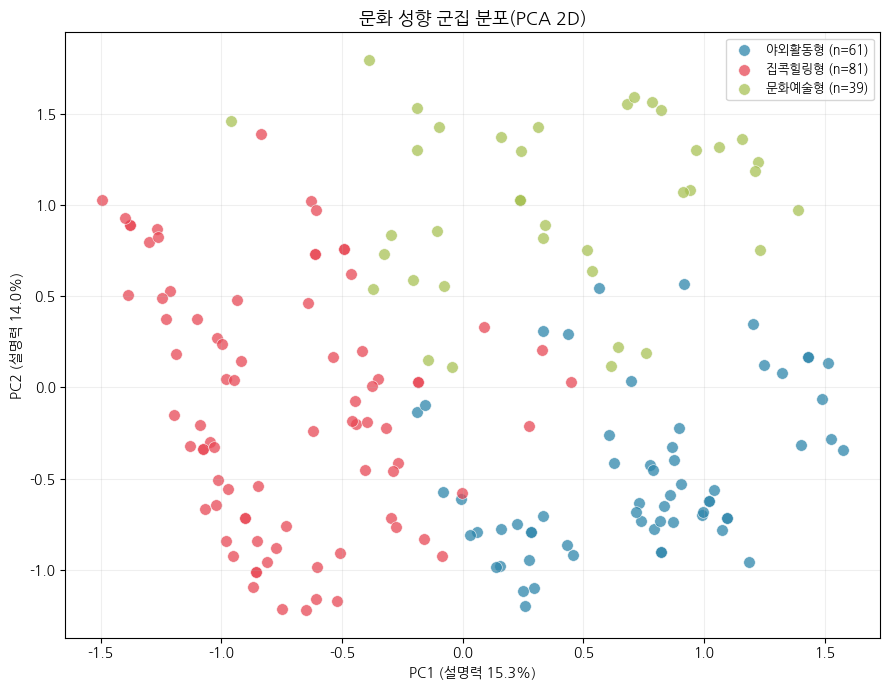

[저장] culture_viz1_pca.png


In [11]:
# 시각화 - PCA 2D 산점도

COLORS = ['#2E86AB', '#E84855', '#A8C256']
labels_order = ['야외활동형', '집콕힐링형', '문화예술형']

cluster_labels_culture = {
    0:'집콕힐링형',
    1:'야외활동형',
    2:'문화예술형'
}

df_survey['cluster_culture_label'] = df_survey['cluster_culture'].map(cluster_labels_culture)

pca = PCA(n_components = 2, random_state = 42)
X_pca = pca.fit_transform(X_culture)
df_survey['pca1_c'] = X_pca[:,0]
df_survey['pca2_c'] = X_pca[:,1]

fig, ax = plt.subplots(figsize=(9,7))
for i, label in enumerate(labels_order):
    mask = df_survey['cluster_culture_label'] == label
    ax.scatter(
        df_survey.loc[mask, 'pca1_c'],
        df_survey.loc[mask, 'pca2_c'],
        c=COLORS[i], label=f"{label} (n={mask.sum()})",
        alpha = 0.75, s=70, edgecolors='white', linewidths=0.5
    )

ax.set_title('문화 성향 군집 분포(PCA 2D)', fontsize=13, fontweight='bold')
ax.set_xlabel(f"PC1 (설명력 {pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 (설명력 {pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.legend(loc='best', fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/culture_viz1_pca.png', dpi=150, bbox_inches='tight')
plt.show()
print('[저장] culture_viz1_pca.png')

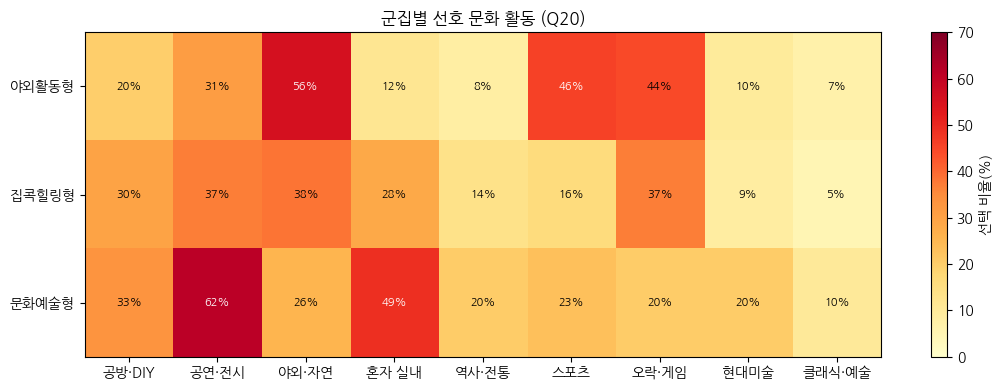

[저장] culture_viz2_q20_heatmap.png


In [12]:
# 시각화 - 군집별 Q20 활동 선호 히트맵

heatmap_data = df_survey.groupby('cluster_culture_label')[q20_cols].mean().mul(100).round(1)
heatmap_data = heatmap_data.reindex(labels_order)
heatmap_data.columns = list(q20_labels_ko.values())

fig, ax = plt.subplots(figsize=(11, 4))

im = ax.imshow(heatmap_data.values, cmap='YlOrRd', aspect='auto', vmin=0, vmax=70)
ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, fontsize=10)
ax.set_yticks(range(len(labels_order)))
ax.set_yticklabels(labels_order, fontsize=10)

for i in range(len(labels_order)):
    for j in range(len(heatmap_data.columns)):
        val = heatmap_data.values[i, j]
        ax.text(j, i, f'{val:.0f}%', ha = 'center', va='center', fontsize=8,
                color='white' if val > 45 else 'black')

plt.colorbar(im, ax=ax, label='선택 비율(%)')
ax.set_title('군집별 선호 문화 활동 (Q20)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/culture_viz2_q20_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('[저장] culture_viz2_q20_heatmap.png')

[레이더 축별 군집 수치]
                       야외 선호  대화 선호  공연·전시  언어 자극  혼자 집중  집안 선호
cluster_culture_label                                          
야외활동형                  1.000  0.541  0.311  0.328  0.115  0.000
집콕힐링형                  0.000  0.222  0.370  0.235  0.346  1.000
문화예술형                  0.872  0.667  0.615  0.564  0.051  0.128


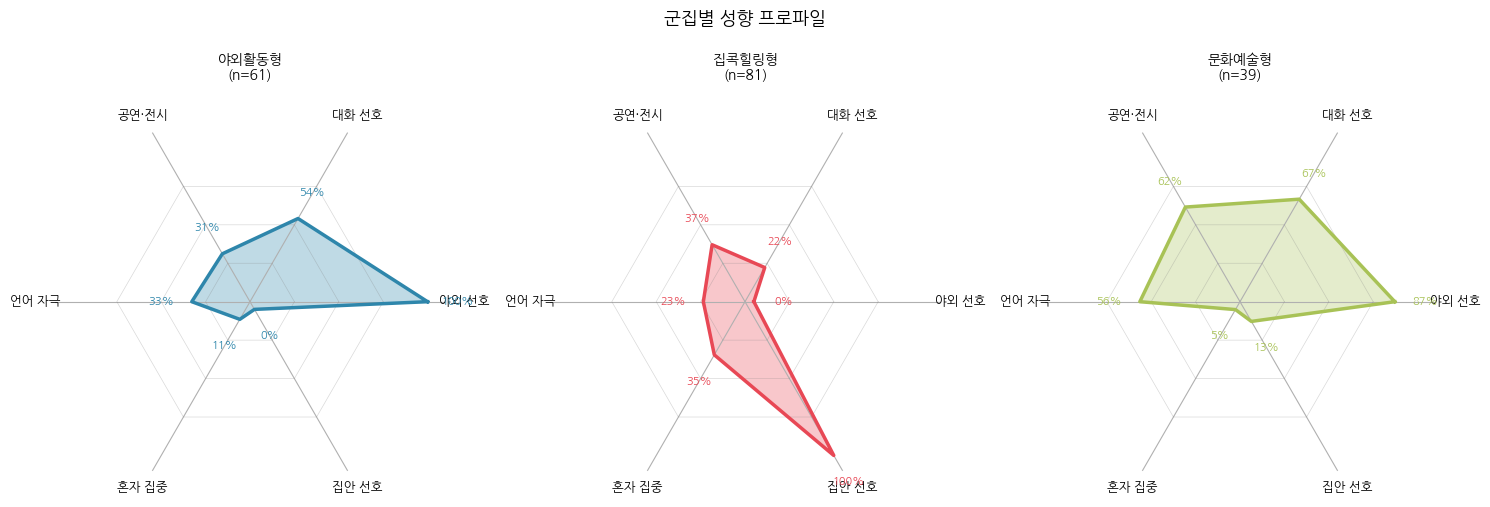

[저장] culture_viz3_radar.png


In [13]:
# 시각화 - 군집별 핵심 특성 레이더 차트

# 레이더용 비율 데이터 계산
radar_data = {
    '야외 선호':df_survey.groupby('cluster_culture_label')['q14_place_pref'].apply(
        lambda x: (x=='야외, 집밖').mean()),
    '대화 선호':df_survey.groupby('cluster_culture_label')['q15_interaction'].apply(
        lambda x: (x=='관심사가 같은 사람들과 가볍게 대화하며 친해지고 싶다').mean()),
    '공연·전시':df_survey.groupby('cluster_culture_label')[q20_cols].apply(
        lambda x: x['q20_concert'].mean()),
    '언어 자극':df_survey.groupby('cluster_culture_label')['q19_stimulus_type'].apply(
        lambda x: (x=='생각과 해석이 필요한 활동 (독서 토론·영화 비평·글쓰기·연극 관람)').mean()),
    '혼자 집중':df_survey.groupby('cluster_culture_label')['q15_interaction'].apply(
        lambda x: (x=='누구의 방해도 없이 온전히 나 혼자 집중하고 싶다').mean()),
    '집안 선호':df_survey.groupby('cluster_culture_label')['q14_place_pref'].apply(
        lambda x: (x == '온라인, 집안').mean())
}
radar_df = pd.DataFrame(radar_data).reindex(labels_order)
radar_labels_r = list(radar_data.keys())
print('[레이더 축별 군집 수치]')
print(radar_df.round(3))

N = len(radar_labels_r)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), subplot_kw=dict(polar=True))

for i, (ax, label) in enumerate(zip(axes, labels_order)):
    raw_values = radar_df.loc[label].tolist()

    # 0값 클리핑 (레이더 차트 찌그러짐 방지)
    plot_values = [max(v, 0.05) for v in raw_values]
    plot_values_closed = plot_values + plot_values[:1]

    # 배경 원 그리기
    for r in [0.25, 0.5, 0.75]:
        ax.plot(angles, [r] * (N+1), color='grey', linewidth=0.5, alpha=0.3)

    ax.plot(angles, plot_values_closed, color=COLORS[i], linewidth=2.5)
    ax.fill(angles, plot_values_closed, color=COLORS[i], alpha=0.3)

    # 각 꼭짓점에 수치 표시 (축 이름과 겹치지 않게 조절: value + n)
    for angle, pv, rv in zip(angles[:-1], plot_values, raw_values):
        ax.text(angle, pv + 0.17, f'{rv*100:.0f}%',
                ha='center', va='center', fontsize=8,
                color=COLORS[i], fontweight='bold')

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(radar_labels_r, fontsize=9)
    ax.set_yticks([])
    ax.set_ylim(0, 1.1)
    ax.spines['polar'].set_visible(False)

    # 군집 이름 + 인원 수
    n = (df_survey['cluster_culture_label'] == label).sum()
    ax.set_title(f'{label}\n(n={n})', fontsize=10, fontweight='bold', pad=20)

plt.suptitle('군집별 성향 프로파일', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/culture_viz3_radar.png', dpi=150, bbox_inches='tight')
plt.show()
print('[저장] culture_viz3_radar.png')

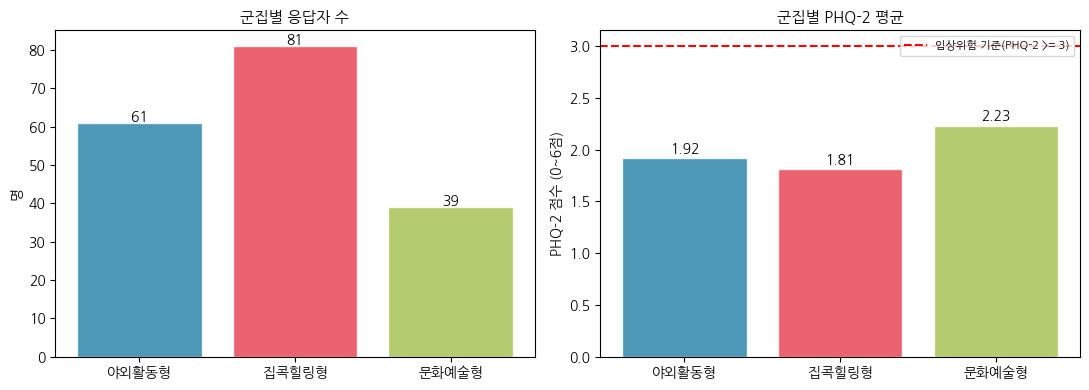

[저장] culture_viz4_overview.png


In [14]:
# 시각화 - 군집 크기 + PHQ-2 분포 (군집별 박스플롯)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sizes = df_survey['cluster_culture_label'].value_counts().reindex(labels_order)
axes[0].bar(labels_order, sizes.values, color=COLORS, alpha=0.85, edgecolor='white')
axes[0].set_title('군집별 응답자 수', fontsize=11, fontweight='bold')
axes[0].set_ylabel('명')
axes[0].tick_params(axis='x')

for i, v in enumerate(sizes.values):
    axes[0].text(i, v+0.5, str(v), ha='center', fontweight='bold')

phq_vals = df_survey.groupby('cluster_culture_label')['phq2'].mean().reindex(labels_order)
axes[1].bar(labels_order, phq_vals.values, color=COLORS, alpha=0.85, edgecolor='white')
axes[1].axhline(3, color='red', linestyle='--', linewidth=1.5, label='임상위험 기준(PHQ-2 >= 3)')
axes[1].set_title('군집별 PHQ-2 평균', fontsize=11, fontweight='bold')
axes[1].set_ylabel('PHQ-2 점수 (0~6점)')
axes[1].tick_params(axis='x')
axes[1].legend(fontsize=8)

for i, v in enumerate(phq_vals.values):
    axes[1].text(i, v+0.05, f"{v:.2f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{IMG_DIR}/culture_viz4_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print('[저장] culture_viz4_overview.png')

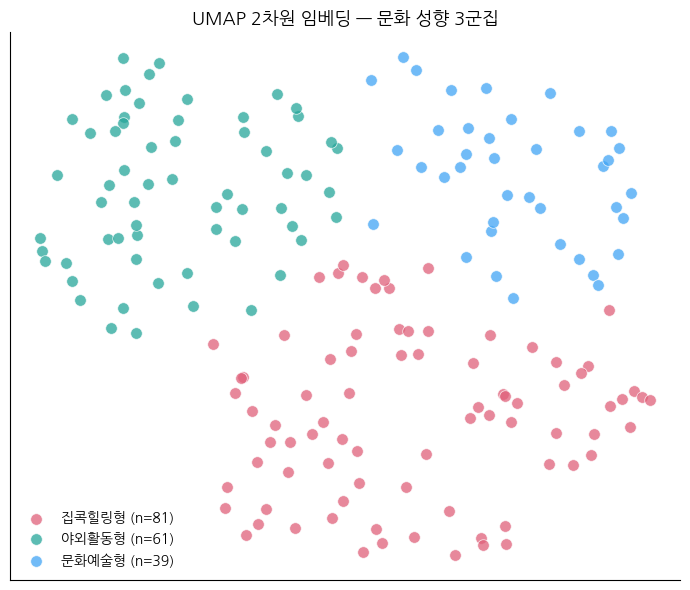

In [15]:
# UMAP 2차원 임베딩 — 군집 분리 정도를 시각적으로 확인
# UMAP은 시각화 도구일 뿐 군집 배정 결과를 바꾸지 않음
# (PCA보다 지역 구조를 강조해 더 잘 갈라져 보일 수 있으므로 해석에 주의)
import umap

CLUSTER_LABELS = {0: "집콕힐링형", 1: "야외활동형", 2: "문화예술형"}
CLUSTER_COLORS = {0: "#E0607A", 1: "#26A69A", 2: "#42A5F5"}


def plot_umap_clusters(X, cluster_labels, n_neighbors=15, min_dist=0.3,
                       save_path=f"{IMG_DIR}/umap_cluster_scatter.png"):
    """
    X              : 군집화에 사용한 피처 행렬 (X_culture)
    cluster_labels : 응답자별 군집 번호 (0/1/2)
    n_neighbors    : 작을수록 지역 구조를 세밀하게 표현 (표본이 작아 5~30 범위에서 비교)
    """
    reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist,
                        metric="euclidean", random_state=42)
    embedding = reducer.fit_transform(X)

    fig, ax = plt.subplots(figsize=(7, 6))
    for c in sorted(CLUSTER_LABELS):
        mask = cluster_labels == c
        ax.scatter(embedding[mask, 0], embedding[mask, 1], s=70, alpha=0.75,
                   color=CLUSTER_COLORS[c], label=f"{CLUSTER_LABELS[c]} (n={mask.sum()})",
                   edgecolor="white", linewidth=0.6)
    ax.set_title("UMAP 2차원 임베딩 — 문화 성향 3군집", fontsize=13, fontweight="bold")
    ax.legend(frameon=False, loc="best")
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    return embedding


embedding = plot_umap_clusters(X_culture, df_survey["cluster_culture"].values)

## 3. 청년 154명 K-means 탐색

- 서비스 대상인 청년(19~34세) 154명만으로 같은 22개 피처를 사용해 재탐색
- 실루엣 점수가 k별로 0.11~0.13 수준으로 낮아, 특정 k에서 뚜렷한 분리가 확인되지 않음

In [16]:
# 청년층(19~34세)만 추출해 같은 입력 피처로 K-means 재탐색
df_youth = df_survey.loc[df_survey["generation"] == "청년(19~34세)"].copy().reset_index(drop=True)
print("청년층 응답자:", len(df_youth))

culture_cols = ["q9_time", "q14_place_pref", "q15_interaction", "q16_healing_spot", "q19_stimulus_type"]
q20_cols = list(q20_map.keys())

# 단일 선택 문항 원핫 + Q20 복수 응답 이진화
ohe_youth = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_ohe_youth = ohe_youth.fit_transform(df_youth[culture_cols])
for col, keyword in q20_map.items():
    df_youth[col] = df_youth["q20_preference_detail"].str.contains(keyword, na=False, regex=False).astype(int)

X_culture_youth = np.hstack([X_ohe_youth, df_youth[q20_cols].to_numpy()])
print("입력 행렬:", X_culture_youth.shape)

# K=2~8 탐색
rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_culture_youth)
    rows.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette_score(X_culture_youth, labels)})
results_youth = pd.DataFrame(rows)
print(results_youth.round(4).to_string(index=False))

청년층 응답자: 154
입력 행렬: (154, 22)
 k  inertia  silhouette
 2 583.4109      0.1279
 3 532.8284      0.1082
 4 492.3321      0.1233
 5 465.8459      0.1209
 6 442.4681      0.1250
 7 426.5273      0.1257
 8 417.3321      0.1137


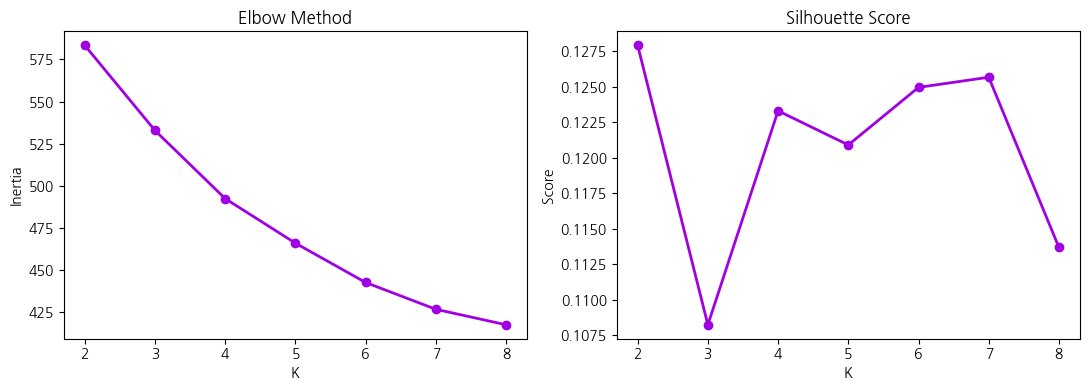

In [17]:
# Elbow · 실루엣 그래프 (포트폴리오용)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title, ylabel in [(axes[0], "inertia", "Elbow Method", "Inertia"),
                               (axes[1], "silhouette", "Silhouette Score", "Score")]:
    ax.plot(results_youth["k"], results_youth[col], marker="o", color="#a000e3", linewidth=2)
    ax.set_title(title)
    ax.set_xlabel("K")
    ax.set_ylabel(ylabel)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/youth_silhouette_score.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
# 비교 기준으로 K=3 학습 후 군집별 응답 분포 확인
km_youth_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df_youth["cluster_culture"] = km_youth_3.fit_predict(X_culture_youth)
print("K=3 군집 크기")
print(df_youth["cluster_culture"].value_counts().sort_index())

for col in culture_cols:
    print(f"\n[{col}]")
    print(pd.crosstab(df_youth["cluster_culture"], df_youth[col], normalize="index").mul(100).round(1))

print("\n[Q20 활동 선호]")
print(df_youth.groupby("cluster_culture")[q20_cols].mean().mul(100).round(1).T)

K=3 군집 크기
cluster_culture
0    44
1    49
2    61
Name: count, dtype: int64

[q9_time]
q9_time          따뜻한 햇살과 밝은 분위기가 어울리는 낮  시간대는 상관없음  조명과 야경, 차분한 분위기가 더해주는 밤  \
cluster_culture                                                               
0                                  40.9       20.5                     29.5   
1                                  49.0       12.2                     28.6   
2                                  34.4       16.4                     42.6   

q9_time          햇살이 환하고 상쾌한 아침  
cluster_culture                  
0                           9.1  
1                          10.2  
2                           6.6  

[q14_place_pref]
q14_place_pref   야외, 집밖  온라인, 집안
cluster_culture                 
0                   0.0    100.0
1                 100.0      0.0
2                  49.2     50.8

[q15_interaction]
q15_interaction  관심사가 같은 사람들과 가볍게 대화하며 친해지고 싶다  누구의 방해도 없이 온전히 나 혼자 집중하고 싶다  \
cluster_culture                                                   

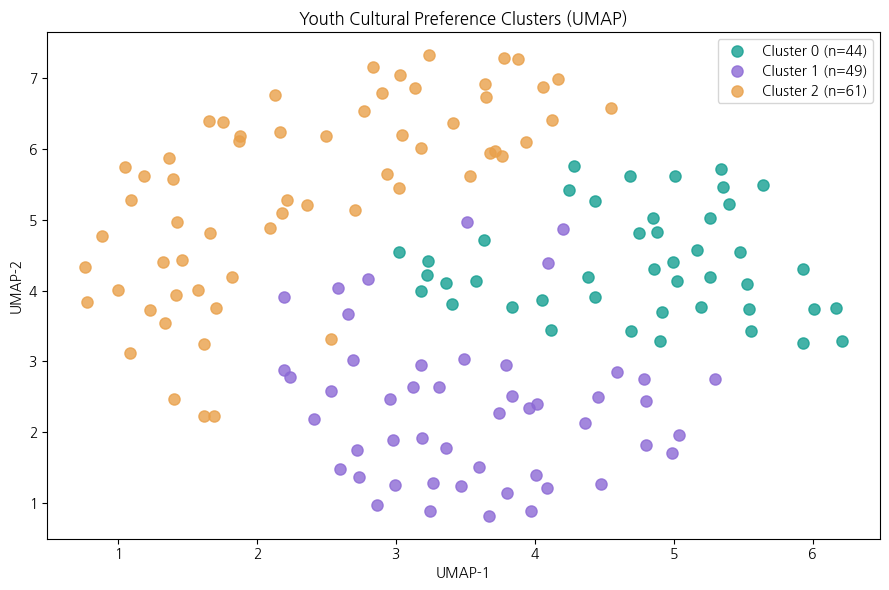

In [19]:
# UMAP 2차원 임베딩 (청년 154명, K=3)
import umap

reducer = umap.UMAP(n_neighbors=30, min_dist=0.3, metric="euclidean", random_state=42)
embedding_youth = reducer.fit_transform(X_culture_youth)

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#159F91", "#8C69D5", "#E9A04A"]
for cluster_id in sorted(df_youth["cluster_culture"].unique()):
    mask = df_youth["cluster_culture"].to_numpy() == cluster_id
    ax.scatter(embedding_youth[mask, 0], embedding_youth[mask, 1], color=colors[cluster_id],
               label=f"Cluster {cluster_id} (n={mask.sum()})", s=65, alpha=0.8)
ax.set_title("Youth Cultural Preference Clusters (UMAP)")
ax.set_xlabel("UMAP-1")
ax.set_ylabel("UMAP-2")
ax.legend()
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/youth_umap_k3.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. 군집 구조 검증

| 검증 | 확인 내용 |
|---|---|
| 4-1 K별 비교 | 실루엣 · 부트스트랩 안정성(ARI) · 군집 프로파일 |
| 4-2 Q14·Q16 영향도 | Cramér's V · 응답 조합 일치도 · 대리 의사결정나무 · 문항 제거 실험(ARI) |
| 4-3 방법 비교 | K-means · K-modes · 계층(해밍·자카드) 간 일치도 |
| 4-4 추천 차별성 | 군집 간 Q20 차이(FDR) · LOO 추천 시뮬레이션 |

In [20]:
# 검증 공통 설정
from scipy.stats import chi2_contingency, fisher_exact
from scipy.special import comb
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import cross_val_score, StratifiedKFold

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

RS = 42
K_LIST = [2, 3, 4, 5, 7]
K_MAIN = 3                                   # 상세 비교 기준 K
FIG_DIR = f"{IMG_DIR}/validation"
os.makedirs(FIG_DIR, exist_ok=True)

In [21]:
# ---- 짧은 라벨 (그래프·표 가독성용) ----
SHORT = {
    "따뜻한 햇살과 밝은 분위기가 어울리는 낮": "낮",
    "시간대는 상관없음": "무관",
    "조명과 야경, 차분한 분위기가 더해주는 밤": "밤",
    "햇살이 환하고 상쾌한 아침": "아침",
    "야외, 집밖": "야외",
    "온라인, 집안": "집안",
    "관심사가 같은 사람들과 가볍게 대화하며 친해지고 싶다": "가벼운 대화",
    "누구의 방해도 없이 온전히 나 혼자 집중하고 싶다": "혼자 집중",
    "말을 섞지 않더라도 같은 공간에 조용히 함께하는 분위기가 좋다": "조용히 함께",
    "에어컨이 시원하고 세련된 인테리어의 조용한 갤러리나 북카페": "갤러리·북카페",
    "피톤치드 가득한 숲속이나 탁 트인 조용한 공원": "숲·공원",
    "생각과 해석이 필요한 활동 (독서 토론·영화 비평·글쓰기·연극 관람)": "해석형",
    "특별한 생각 없이 감각에 몰입하는 활동 (미디어아트·음악 감상·풍경화)": "감각형",
}
Q_SHORT = {
    "q9_time": "Q9 시간대", "q12_lonely": "Q12 고립감",
    "q14_place_pref": "Q14 장소", "q15_interaction": "Q15 소통",
    "q16_healing_spot": "Q16 힐링장소", "q19_stimulus_type": "Q19 자극",
}
Q20_SHORT = {
    "q20_craft": "Q20 공방·DIY", "q20_concert": "Q20 공연·전시",
    "q20_outdoor": "Q20 야외·자연", "q20_cafe": "Q20 혼자 실내",
    "q20_heritage": "Q20 역사·전통", "q20_sport": "Q20 스포츠",
    "q20_fun": "Q20 오락·게임", "q20_modern": "Q20 현대미술",
    "q20_classic": "Q20 클래식",
}

def short_val(v):
    v = str(v).strip()
    return SHORT.get(v, v[:12])

def pretty(name):
    """OneHot 피처명 → 'Q14 장소: 야외' 형태"""
    for col in Q_SHORT:
        if name.startswith(col + "_"):
            return f"{Q_SHORT[col]}: {short_val(name[len(col) + 1:])}"
    return Q20_SHORT.get(name, name)

def qname(col):
    return Q_SHORT.get(col, Q20_SHORT.get(col, col))

In [22]:
# ---- 공통 함수 ----
def build_matrix(df, cat_cols, use_q20=True, drop_binary=False):
    """범주형 원핫 + Q20 이진 결합. drop_binary=True면 2지선다 문항은 더미 1개만 사용(가중치 ½)."""
    blocks, names = [], []
    if cat_cols:
        enc = OneHotEncoder(sparse_output=False, handle_unknown="ignore",
                            drop="if_binary" if drop_binary else None)
        blocks.append(enc.fit_transform(df[cat_cols]))
        names += list(enc.get_feature_names_out(cat_cols))
    if use_q20:
        blocks.append(df[q20_cols].to_numpy())
        names += list(q20_cols)
    return np.hstack(blocks).astype(float), names


def run_kmeans(X, k, seed=RS):
    return KMeans(n_clusters=k, random_state=seed, n_init=10).fit_predict(X)


def cramers_v(x, y):
    ct = pd.crosstab(np.asarray(x), np.asarray(y))
    if min(ct.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(ct, correction=False)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))


def sizes_str(labels):
    return " / ".join(str(v) for v in pd.Series(labels).value_counts().sort_index())


def cluster_profile(X, names, labels):
    prof = pd.DataFrame(X, columns=names).groupby(np.asarray(labels)).mean().mul(100).T
    prof.columns = [f"C{c} (n={(np.asarray(labels) == c).sum()})" for c in prof.columns]
    prof.index = [pretty(n) for n in prof.index]
    return prof


def top_lifts(X, names, labels, n=4):
    """군집별로 전체 대비 응답 비율이 가장 높은 특징 n개 (%p)"""
    df = pd.DataFrame(X, columns=[pretty(c) for c in names])
    overall = df.mean()
    labels = np.asarray(labels)
    rows = []
    for c in sorted(np.unique(labels)):
        diff = (df[labels == c].mean() - overall).mul(100).sort_values(ascending=False)
        rows.append({
            "군집": f"C{c}" if isinstance(c, (int, np.integer)) else c, "n": int((labels == c).sum()),
            "두드러진 특징 (전체 대비 %p)": ", ".join(f"{i} {v:+.0f}" for i, v in diff.head(n).items()),
        })
    return pd.DataFrame(rows).set_index("군집")


def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")


def bh_fdr(p):
    """Benjamini-Hochberg FDR 보정 q-value"""
    p = np.asarray(p, float)
    order = np.argsort(p)
    q = p[order] * len(p) / np.arange(1, len(p) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[order] = np.clip(q, 0, 1)
    return out

In [23]:
# ---- 기준 입력 행렬 & Q14×Q16 응답 조합 ----
X_base, FEATS = build_matrix(df_youth, culture_cols)
FEATS_PRETTY = [pretty(f) for f in FEATS]
combo = (df_youth["q14_place_pref"].map(short_val) + " × "
         + df_youth["q16_healing_spot"].map(short_val)).to_numpy()

labels_by_k = {k: run_kmeans(X_base, k) for k in K_LIST}

print(f"입력 행렬: {X_base.shape}  |  사용 문항: {[qname(c) for c in culture_cols]} + Q20 {len(q20_cols)}개")
print("\n[Q14 × Q16 응답 조합 분포]")
print(pd.Series(combo).value_counts().to_string())

입력 행렬: (154, 22)  |  사용 문항: ['Q9 시간대', 'Q14 장소', 'Q15 소통', 'Q16 힐링장소', 'Q19 자극'] + Q20 9개

[Q14 × Q16 응답 조합 분포]
야외 × 숲·공원       49
집안 × 숲·공원       44
집안 × 갤러리·북카페    31
야외 × 갤러리·북카페    30


### 4-1. K별 군집 특성 비교

In [24]:
# 4-1-1. 지표 요약: 실루엣 + 부트스트랩 안정성(ARI)
#   - 실루엣 < 0.25 : 구조가 약함 (원핫 이진 데이터에서는 흔한 수준)
#   - 안정성 ARI ≥ 0.75 안정 / 0.6~0.75 보통 / < 0.6 불안정 (관례적 기준)
#   → 실루엣이 낮아도 '재표본에서 같은 군집이 반복되는지'가 실무 근거가 됩니다.

def bootstrap_stability(X, k, B=50, seed=RS):
    rng = np.random.default_rng(seed)
    ref = KMeans(n_clusters=k, random_state=seed, n_init=10).fit(X)
    aris = []
    for b in range(B):
        idx = rng.choice(len(X), len(X), replace=True)
        m = KMeans(n_clusters=k, random_state=b, n_init=10).fit(X[idx])
        aris.append(adjusted_rand_score(ref.labels_, m.predict(X)))
    return np.mean(aris), np.std(aris)

rows = []
for k in K_LIST:
    lab = labels_by_k[k]
    st_mean, st_sd = bootstrap_stability(X_base, k)
    rows.append({
        "K": k,
        "실루엣": silhouette_score(X_base, lab),
        "안정성 ARI": st_mean,
        "안정성 SD": st_sd,
        "최소 군집 비율(%)": pd.Series(lab).value_counts().min() / len(lab) * 100,
        "군집 크기": sizes_str(lab),
    })
summary_k = pd.DataFrame(rows).set_index("K")
print("[4-1-1] K별 지표 요약")
print(summary_k.round(3).to_string())

[4-1-1] K별 지표 요약
     실루엣  안정성 ARI  안정성 SD  최소 군집 비율(%)                             군집 크기
K                                                                       
2  0.128    0.473   0.489       39.610                           93 / 61
3  0.108    0.481   0.176       28.571                      44 / 49 / 61
4  0.123    0.622   0.200       20.779                 44 / 34 / 44 / 32
5  0.121    0.510   0.128       16.883            26 / 32 / 37 / 28 / 31
7  0.126    0.478   0.091        9.091  26 / 23 / 22 / 31 / 14 / 17 / 21


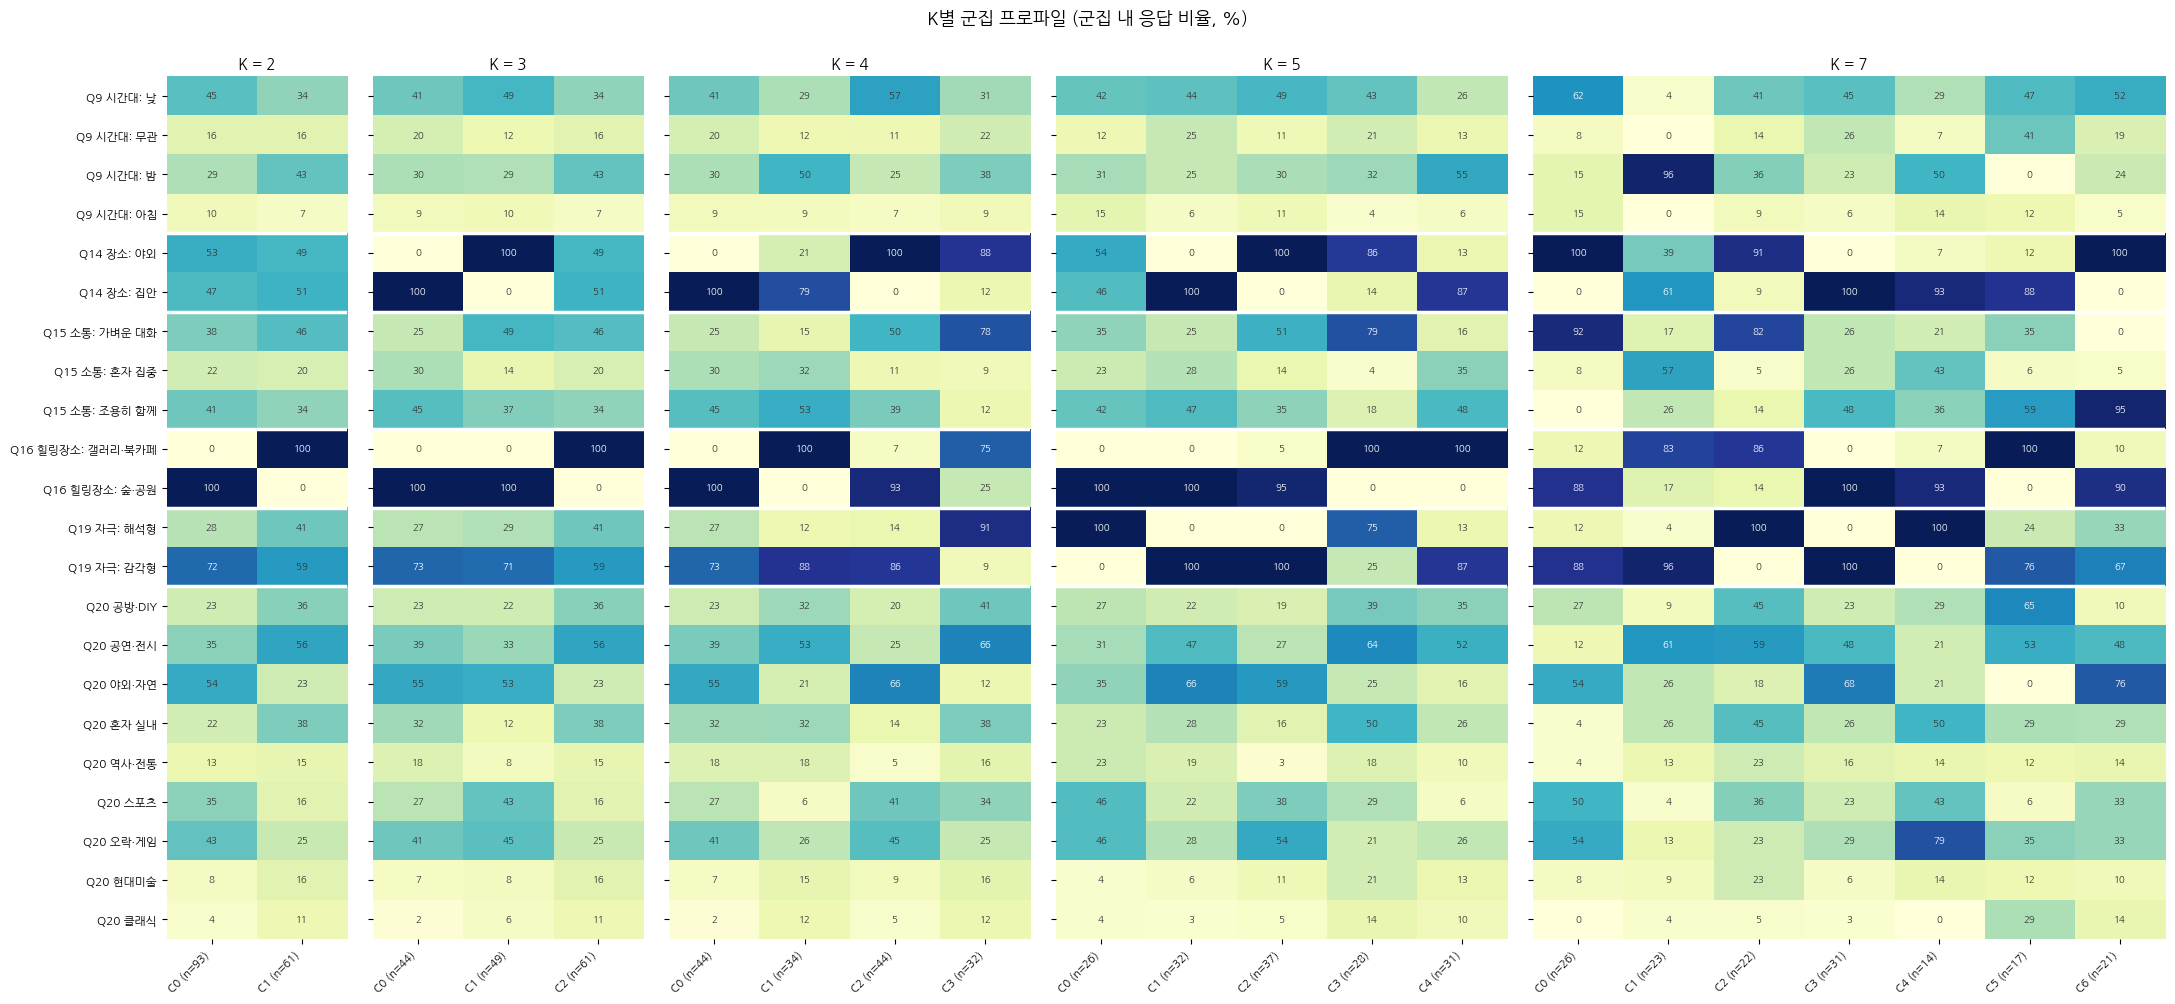

In [25]:
# 4-1-2. K별 프로파일 히트맵 (군집 내 응답 비율 %)
n_cols_total = sum(K_LIST)
fig, axes = plt.subplots(1, len(K_LIST), figsize=(4 + 0.85 * n_cols_total, 10),
                         gridspec_kw={"width_ratios": K_LIST}, sharey=True)

# 문항 경계선 위치
groups = [f.split(":")[0] if ":" in f else "Q20" for f in FEATS_PRETTY]
bounds = [i - 0.5 for i in range(1, len(groups)) if groups[i] != groups[i - 1]]

for ax, k in zip(axes, K_LIST):
    prof = cluster_profile(X_base, FEATS, labels_by_k[k])
    ax.imshow(prof.values, cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
    for i in range(prof.shape[0]):
        for j in range(prof.shape[1]):
            v = prof.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 60 else "#333333")
    for b in bounds:
        ax.axhline(b, color="white", linewidth=2.5)
    ax.set_xticks(range(k))
    ax.set_xticklabels(prof.columns, rotation=45, ha="right", fontsize=8)
    ax.set_title(f"K = {k}", fontsize=11, fontweight="bold")
    for s in ax.spines.values():
        s.set_visible(False)

axes[0].set_yticks(range(len(FEATS_PRETTY)))
axes[0].set_yticklabels(FEATS_PRETTY, fontsize=8.5)
fig.suptitle("K별 군집 프로파일 (군집 내 응답 비율, %)", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
save(fig, "1_profile_by_k.png")
plt.show()

In [26]:
# 4-1-3. K별 군집의 두드러진 특징
print("\n[4-1-3] K별 군집 특징 요약")
for k in K_LIST:
    print(f"\n── K = {k}")
    print(top_lifts(X_base, FEATS, labels_by_k[k]).to_string())


# 4-1-4. K가 늘 때 군집이 어떻게 쪼개지는지 (중첩 구조 확인)
print("\n[4-1-4] K 증가에 따른 군집 분할")
for k1, k2 in zip(K_LIST[:-1], K_LIST[1:]):
    ct = pd.crosstab(labels_by_k[k1], labels_by_k[k2],
                     rownames=[f"K={k1}"], colnames=[f"K={k2}"])
    print(f"\n{ct.to_string()}")


[4-1-3] K별 군집 특징 요약

── K = 2
     n                                                 두드러진 특징 (전체 대비 %p)
군집                                                                       
C0  93        Q16 힐링장소: 숲·공원 +40, Q20 야외·자연 +12, Q20 스포츠 +8, Q20 오락·게임 +7
C1  61  Q16 힐링장소: 갤러리·북카페 +60, Q20 공연·전시 +12, Q20 혼자 실내 +10, Q9 시간대: 밤 +8

── K = 3
     n                                                   두드러진 특징 (전체 대비 %p)
군집                                                                         
C0  44  Q14 장소: 집안 +51, Q16 힐링장소: 숲·공원 +40, Q20 야외·자연 +13, Q15 소통: 혼자 집중 +9
C1  49       Q14 장소: 야외 +49, Q16 힐링장소: 숲·공원 +40, Q20 스포츠 +15, Q20 야외·자연 +12
C2  61    Q16 힐링장소: 갤러리·북카페 +60, Q20 공연·전시 +12, Q20 혼자 실내 +10, Q9 시간대: 밤 +8

── K = 4
     n                                                          두드러진 특징 (전체 대비 %p)
군집                                                                                
C0  44         Q14 장소: 집안 +51, Q16 힐링장소: 숲·공원 +40, Q20 야외·자연 +13, Q15 소통: 혼자 집중 +9
C1  34       Q16 힐링장소: 갤

### 4-2. Q14 · Q16 영향도

- 원핫 + 유클리드 거리에서 50:50에 가까운 2지선다(Q14·Q16)는 K-means가 가장 먼저 자르기 쉬운 문항
- 두 문항만으로 K=3 군집 예측 정확도 **96.1%**(depth 2 의사결정나무, 5-fold), 두 문항 제외 후 재군집화 시 기준 대비 **ARI 0.097**

[4-2-1] 문항별 Cramér's V (높을수록 군집을 강하게 가르는 문항)
              K=2    K=3    K=4    K=5    K=7
Q16 힐링장소    1.000  1.000  0.872  0.974  0.833
Q14 장소      0.034  0.777  0.874  0.808  0.860
Q20 야외·자연   0.306  0.306  0.449  0.398  0.525
Q20 스포츠     0.208  0.248  0.286  0.299  0.359
Q20 혼자 실내   0.177  0.245  0.207  0.251  0.305
Q20 공연·전시   0.200  0.205  0.303  0.276  0.357
Q20 오락·게임   0.188  0.191  0.184  0.271  0.381
Q15 소통      0.083  0.155  0.341  0.319  0.577
Q20 클래식     0.136  0.148  0.171  0.158  0.348
Q20 공방·DIY  0.147  0.147  0.175  0.176  0.386
Q20 현대미술    0.138  0.139  0.117  0.186  0.168
Q19 자극      0.135  0.136  0.640  0.863  0.817
Q9 시간대      0.149  0.125  0.153  0.170  0.381
Q20 역사·전통   0.026  0.116  0.170  0.217  0.159


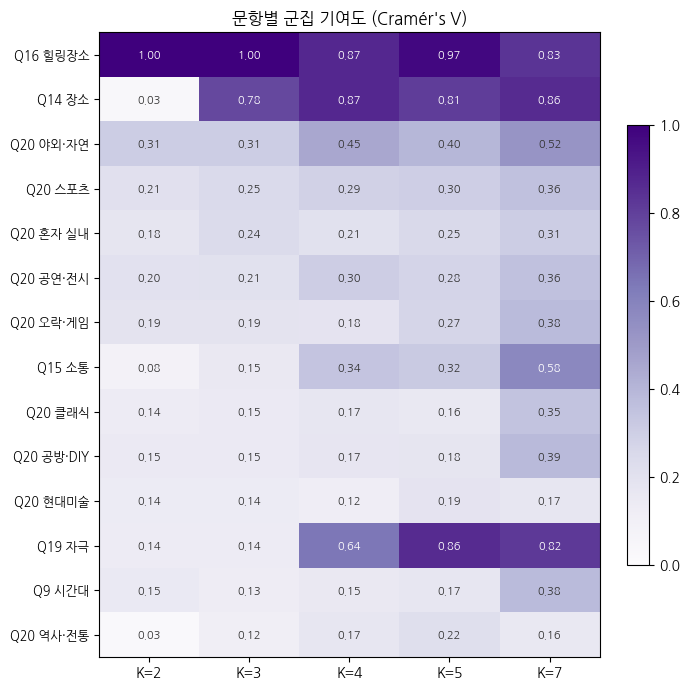

In [27]:
# 참고: 원핫 + 유클리드 거리에서는 단일선택 문항의 응답이 다르면 거리²가 2,
#       Q20 항목 하나가 다르면 1만큼 늘어납니다. 50:50에 가까운 2지선다(Q14·Q16)는
#       한 축으로 깔끔하게 나뉘어 K-means가 가장 먼저 자르기 쉬운 문항입니다.

# 4-2-1. 문항별 Cramér's V (군집 라벨과의 연관도, 0~1)
assoc_cols = list(culture_cols) + list(q20_cols)
cv_table = pd.DataFrame({
    f"K={k}": {qname(c): cramers_v(df_youth[c], labels_by_k[k]) for c in assoc_cols}
    for k in K_LIST
})
cv_table = cv_table.sort_values(f"K={K_MAIN}", ascending=False)
print("[4-2-1] 문항별 Cramér's V (높을수록 군집을 강하게 가르는 문항)")
print(cv_table.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(cv_table.values, cmap="Purples", vmin=0, vmax=1, aspect="auto")
for i in range(cv_table.shape[0]):
    for j in range(cv_table.shape[1]):
        v = cv_table.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.55 else "#333333")
ax.set_xticks(range(cv_table.shape[1]))
ax.set_xticklabels(cv_table.columns)
ax.set_yticks(range(cv_table.shape[0]))
ax.set_yticklabels(cv_table.index, fontsize=9)
ax.set_title("문항별 군집 기여도 (Cramér's V)", fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
save(fig, "2_cramers_v.png")
plt.show()

In [28]:
# 4-2-2. 군집 = Q14×Q16 응답 조합인가?
#   NMI가 1에 가깝고 순도가 높으면 '두 문항 조합으로 나눈 것'에 가깝습니다.
rows = []
for k in K_LIST:
    lab = labels_by_k[k]
    ct = pd.crosstab(lab, combo)
    rows.append({
        "K": k,
        "NMI(군집 vs 조합)": normalized_mutual_info_score(combo, lab),
        "ARI(군집 vs 조합)": adjusted_rand_score(combo, lab),
        "조합 순도(%)": ct.max(axis=1).sum() / len(lab) * 100,
    })
combo_match = pd.DataFrame(rows).set_index("K")
print("\n[4-2-2] 군집 라벨 vs Q14×Q16 조합 일치도")
print(combo_match.round(3).to_string())

print(f"\n[K={K_MAIN}] 군집 × Q14·Q16 조합 교차표 (명)")
print(pd.crosstab(labels_by_k[K_MAIN], combo, rownames=["군집"], colnames=["Q14 × Q16"]).to_string())


[4-2-2] 군집 라벨 vs Q14×Q16 조합 일치도
   NMI(군집 vs 조합)  ARI(군집 vs 조합)  조합 순도(%)
K                                        
2          0.660          0.485    51.948
3          0.888          0.812    80.519
4          0.725          0.722    85.714
5          0.704          0.621    85.714
7          0.558          0.447    84.416

[K=3] 군집 × Q14·Q16 조합 교차표 (명)
Q14 × Q16  야외 × 갤러리·북카페  야외 × 숲·공원  집안 × 갤러리·북카페  집안 × 숲·공원
군집                                                         
0                     0          0             0         44
1                     0         49             0          0
2                    30          0            31          0


In [29]:
# 4-2-3. 대리 의사결정나무: 몇 번의 질문으로 군집 라벨을 재현할 수 있는가
#   depth 2(=두 문항)로 정확도 90%+ 이면 군집이 사실상 2개 문항 규칙에 가깝습니다.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
idx_q14_q16 = [i for i, f in enumerate(FEATS)
               if f.startswith("q14_place_pref_") or f.startswith("q16_healing_spot_")]

rows = []
for k in K_LIST:
    y = labels_by_k[k]
    row = {"K": k}
    for d in [1, 2, 3, 4]:
        row[f"depth {d}"] = cross_val_score(
            DecisionTreeClassifier(max_depth=d, random_state=RS), X_base, y, cv=skf).mean()
    row["Q14·Q16만 사용"] = cross_val_score(
        DecisionTreeClassifier(random_state=RS), X_base[:, idx_q14_q16], y, cv=skf).mean()
    rows.append(row)
tree_acc = pd.DataFrame(rows).set_index("K")
print("\n[4-2-3] 대리 의사결정나무 교차검증 정확도")
print(tree_acc.round(3).to_string())

tree_main = DecisionTreeClassifier(max_depth=2, random_state=RS).fit(X_base, labels_by_k[K_MAIN])
print(f"\n[K={K_MAIN}] depth 2 규칙")
print(export_text(tree_main, feature_names=FEATS_PRETTY, decimals=1))


[4-2-3] 대리 의사결정나무 교차검증 정확도
   depth 1  depth 2  depth 3  depth 4  Q14·Q16만 사용
K                                                 
2    1.000    1.000    1.000    1.000        1.000
3    0.714    1.000    1.000    1.000        1.000
4    0.571    0.857    0.877    0.903        0.857
5    0.429    0.682    0.896    0.902        0.766
7    0.370    0.572    0.818    0.792        0.546

[K=3] depth 2 규칙
|--- Q16 힐링장소: 숲·공원 <= 0.5
|   |--- class: 2
|--- Q16 힐링장소: 숲·공원 >  0.5
|   |--- Q14 장소: 집안 <= 0.5
|   |   |--- class: 1
|   |--- Q14 장소: 집안 >  0.5
|   |   |--- class: 0



In [30]:
# 4-2-4. 제거 실험: Q14/Q16을 빼거나 가중치를 낮춰도 같은 군집이 나오는가
#   ARI(기준 대비)가 크게 떨어지면 → 기존 군집은 해당 문항에 의존
variants = {
    "기준(전체)":         (list(culture_cols), False),
    "Q14 제외":           ([c for c in culture_cols if c != "q14_place_pref"], False),
    "Q16 제외":           ([c for c in culture_cols if c != "q16_healing_spot"], False),
    "Q14·Q16 제외":       ([c for c in culture_cols if c not in ("q14_place_pref", "q16_healing_spot")], False),
    "2지선다 가중치 ½":   (list(culture_cols), True),
}

rows, ablation_labels = [], {}
for vname, (cols, drop_bin) in variants.items():
    Xv, _ = build_matrix(df_youth, cols, drop_binary=drop_bin)
    for k in K_LIST:
        lab = run_kmeans(Xv, k)
        ablation_labels[(vname, k)] = (Xv, lab)
        rows.append({
            "변형": vname, "K": k,
            "실루엣": silhouette_score(Xv, lab),
            "ARI(기준 대비)": adjusted_rand_score(labels_by_k[k], lab),
            "NMI(Q14×Q16 조합)": normalized_mutual_info_score(combo, lab),
        })
ablation = pd.DataFrame(rows)
print("\n[4-2-4] 제거 실험")
for metric in ["실루엣", "ARI(기준 대비)", "NMI(Q14×Q16 조합)"]:
    print(f"\n── {metric}")
    print(ablation.pivot(index="변형", columns="K", values=metric)
          .reindex(variants.keys()).round(3).to_string())


[4-2-4] 제거 실험

── 실루엣
K               2      3      4      5      7
변형                                           
기준(전체)      0.128  0.108  0.123  0.121  0.126
Q14 제외      0.144  0.125  0.127  0.138  0.111
Q16 제외      0.137  0.123  0.133  0.126  0.137
Q14·Q16 제외  0.152  0.118  0.127  0.144  0.127
2지선다 가중치 ½  0.114  0.137  0.106  0.112  0.116

── ARI(기준 대비)
K               2      3      4      5      7
변형                                           
기준(전체)      1.000  1.000  1.000  1.000  1.000
Q14 제외      1.000  0.599  0.376  0.319  0.381
Q16 제외     -0.005  0.220  0.326  0.229  0.478
Q14·Q16 제외  0.028  0.013  0.155  0.191  0.237
2지선다 가중치 ½  0.009  0.012  0.079  0.207  0.245

── NMI(Q14×Q16 조합)
K               2      3      4      5      7
변형                                           
기준(전체)      0.660  0.888  0.725  0.704  0.558
Q14 제외      0.660  0.561  0.510  0.449  0.440
Q16 제외      0.674  0.399  0.500  0.247  0.402
Q14·Q16 제외  0.029  0.045  0.042  0.042  0.060
2지선다 가중치 ½  0.050  0.0

In [31]:
# Q14·Q16을 빼면 어떤 구조가 남는지
Xv, lab = ablation_labels[("Q14·Q16 제외", K_MAIN)]
_, names_v = build_matrix(df_youth, variants["Q14·Q16 제외"][0])
print(f"\n[Q14·Q16 제외, K={K_MAIN}] 남은 군집 특징")
print(top_lifts(Xv, names_v, lab).to_string())
print("\n(참고) 이 군집에서 Q14·Q16 분포 — 입력에서 뺐는데도 갈리면 다른 문항과 연동된 '진짜 성향'일 가능성")
print(pd.crosstab(lab, combo, normalize="index").mul(100).round(1).to_string())


[Q14·Q16 제외, K=3] 남은 군집 특징
     n                                                     두드러진 특징 (전체 대비 %p)
군집                                                                           
C0  66  Q19 자극: 감각형 +33, Q15 소통: 조용히 함께 +25, Q15 소통: 혼자 집중 +16, Q20 야외·자연 +11
C1  51          Q19 자극: 해석형 +67, Q15 소통: 가벼운 대화 +10, Q20 스포츠 +9, Q20 혼자 실내 +9
C2  37      Q15 소통: 가벼운 대화 +59, Q19 자극: 감각형 +33, Q20 오락·게임 +13, Q9 시간대: 아침 +5

(참고) 이 군집에서 Q14·Q16 분포 — 입력에서 뺐는데도 갈리면 다른 문항과 연동된 '진짜 성향'일 가능성
col_0  야외 × 갤러리·북카페  야외 × 숲·공원  집안 × 갤러리·북카페  집안 × 숲·공원
row_0                                                  
0              10.6       25.8          27.3       36.4
1              33.3       27.5          15.7       23.5
2              16.2       48.6          13.5       21.6


### 4-3. 범주형 군집화 방법 비교

In [32]:
# 4-3-1. 방법별 비교
#   - K-modes      : 범주 일치/불일치(해밍) 기반. 단, Q20 9개 항목이 각각 1문항 취급 → Q20 비중↑
#   - 계층(해밍)    : 원문항 14개(단일선택 5 + Q20 9) 해밍 거리, average linkage
#   - 계층(자카드)  : 원핫 22개 이진 벡터, '둘 다 선택 안 함(0-0)'을 유사성으로 치지 않음 → 다중응답에 적합
#   실루엣은 공통 기준(해밍)과 각 방법 고유 거리 두 가지로 봅니다.
from kmodes.kmodes import KModes   # pip install kmodes

cat_df = df_youth[culture_cols].astype(str).copy()
for c in q20_cols:
    cat_df[c] = df_youth[c].astype(str)
codes = cat_df.apply(lambda s: pd.factorize(s)[0]).to_numpy()

D_ham = squareform(pdist(codes, metric="hamming"))
D_jac = squareform(pdist(X_base.astype(bool), metric="jaccard"))
D_euc = squareform(pdist(X_base, metric="euclidean"))


def run_kmodes(k):
    return KModes(n_clusters=k, init="Huang", n_init=10,
                  random_state=RS, verbose=0).fit_predict(cat_df.to_numpy())


def run_hier(D, k, linkage="average"):
    try:
        model = AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage=linkage)
    except TypeError:  # sklearn < 1.2
        model = AgglomerativeClustering(n_clusters=k, affinity="precomputed", linkage=linkage)
    return model.fit_predict(D)


METHODS = {
    "K-means (원핫·유클리드)": (lambda k: labels_by_k[k], D_euc),
    "K-modes (해밍)":          (run_kmodes, D_ham),
    "계층 (해밍·average)":      (lambda k: run_hier(D_ham, k), D_ham),
    "계층 (자카드·average)":    (lambda k: run_hier(D_jac, k), D_jac),
}

rows, method_labels = [], {}
for mname, (fn, D_native) in METHODS.items():
    for k in K_LIST:
        lab = np.asarray(fn(k))
        method_labels[(mname, k)] = lab
        rows.append({
            "방법": mname, "K": k,
            "실루엣(해밍, 공통)": silhouette_score(D_ham, lab, metric="precomputed"),
            "실루엣(고유 거리)": silhouette_score(D_native, lab, metric="precomputed"),
            "ARI(K-means 대비)": adjusted_rand_score(labels_by_k[k], lab),
            "NMI(Q14×Q16 조합)": normalized_mutual_info_score(combo, lab),
            "최소 군집(명)": int(pd.Series(lab).value_counts().min()),
            "군집 크기": sizes_str(lab),
        })
method_cmp = pd.DataFrame(rows)
print("[4-3-1] 방법별 비교")
for metric in ["실루엣(해밍, 공통)", "실루엣(고유 거리)", "ARI(K-means 대비)", "NMI(Q14×Q16 조합)", "최소 군집(명)"]:
    print(f"\n── {metric}")
    print(method_cmp.pivot(index="방법", columns="K", values=metric)
          .reindex(METHODS.keys()).round(3).to_string())

print(f"\n[4-3-2] K={K_MAIN} 방법별 군집 특징")
for mname in METHODS:
    lab = method_labels[(mname, K_MAIN)]
    print(f"\n── {mname}  (크기 {sizes_str(lab)})")
    print(top_lifts(X_base, FEATS, lab).to_string())

[4-3-1] 방법별 비교

── 실루엣(해밍, 공통)
K                      2      3      4      5      7
방법                                                  
K-means (원핫·유클리드)  0.187  0.143  0.158  0.148  0.154
K-modes (해밍)       0.165  0.153  0.144  0.121  0.133
계층 (해밍·average)    0.214  0.181  0.151  0.125  0.128
계층 (자카드·average)   0.180  0.143  0.039  0.074  0.116

── 실루엣(고유 거리)
K                      2      3      4      5      7
방법                                                  
K-means (원핫·유클리드)  0.128  0.108  0.123  0.121  0.126
K-modes (해밍)       0.165  0.153  0.144  0.121  0.133
계층 (해밍·average)    0.214  0.181  0.151  0.125  0.128
계층 (자카드·average)   0.152  0.132  0.096  0.115  0.134

── ARI(K-means 대비)
K                      2      3      4      5      7
방법                                                  
K-means (원핫·유클리드)  1.000  1.000  1.000  1.000  1.000
K-modes (해밍)       0.292  0.139  0.311  0.205  0.176
계층 (해밍·average)   -0.020 -0.004  0.020  0.015  0.138
계층 (자카드·average)   0.948  0.602  


[4-3-3] K=3 방법 간 ARI
                   K-means (원핫·유클리드)  K-modes (해밍)  계층 (해밍·average)  계층 (자카드·average)
K-means (원핫·유클리드)              1.000         0.139           -0.004             0.602
K-modes (해밍)                   0.139         1.000            0.009             0.184
계층 (해밍·average)               -0.004         0.009            1.000             0.022
계층 (자카드·average)               0.602         0.184            0.022             1.000


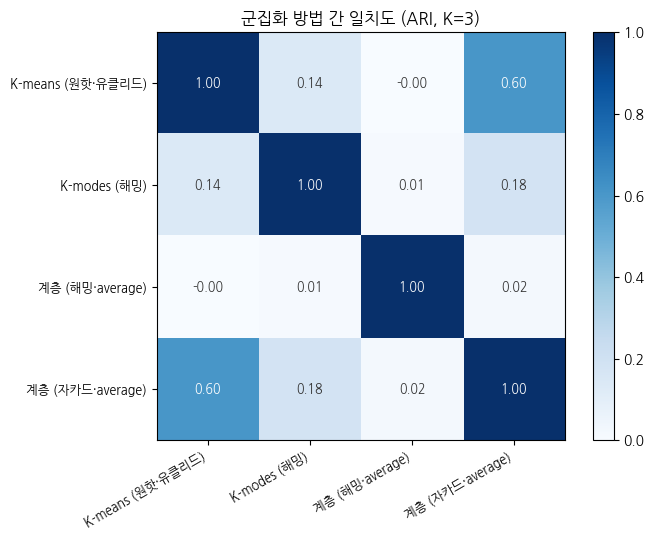

In [33]:
# 4-3-3. 방법 간 일치도 (ARI) — 방법이 달라도 비슷하게 나뉘면 군집 구조가 견고
names_m = list(METHODS.keys())
ari_mat = pd.DataFrame(
    [[adjusted_rand_score(method_labels[(a, K_MAIN)], method_labels[(b, K_MAIN)]) for b in names_m]
     for a in names_m],
    index=names_m, columns=names_m)
print(f"\n[4-3-3] K={K_MAIN} 방법 간 ARI")
print(ari_mat.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(ari_mat.values, cmap="Blues", vmin=0, vmax=1)
for i in range(len(names_m)):
    for j in range(len(names_m)):
        v = ari_mat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.6 else "#333333")
ax.set_xticks(range(len(names_m)))
ax.set_xticklabels(names_m, rotation=30, ha="right", fontsize=9)
ax.set_yticks(range(len(names_m)))
ax.set_yticklabels(names_m, fontsize=9)
ax.set_title(f"군집화 방법 간 일치도 (ARI, K={K_MAIN})", fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
save(fig, "3_method_ari.png")
plt.show()

### 4-4. 군집별 추천 차별성

In [34]:
# 4-4-1. 군집 간 Q20(활동 선호) 차이의 통계적 유의성 (BH-FDR 보정)
#   ※ Q20이 군집 입력에 포함돼 있어 유의하게 나오는 게 당연함(순환) → 4-4-2가 핵심 검증
lab_main = labels_by_k[K_MAIN]
rows = []
for c in q20_cols:
    ct = pd.crosstab(lab_main, df_youth[c])
    p = chi2_contingency(ct)[1] if min(ct.shape) > 1 else 1.0
    rows.append({"활동": Q20_SHORT[c], "p": p, "Cramér's V": cramers_v(df_youth[c], lab_main),
                 **{f"C{g}(%)": df_youth.loc[lab_main == g, c].mean() * 100 for g in sorted(np.unique(lab_main))}})
q20_test = pd.DataFrame(rows).set_index("활동")
q20_test["q(FDR)"] = bh_fdr(q20_test["p"])
print(f"[4-4-1] K={K_MAIN} 군집 간 Q20 활동 선호 차이")
print(q20_test.round(3).to_string())

[4-4-1] K=3 군집 간 Q20 활동 선호 차이
                p  Cramér's V   C0(%)   C1(%)   C2(%)  q(FDR)
활동                                                           
Q20 공방·DIY  0.189       0.147  22.727  22.449  36.066   0.243
Q20 공연·전시   0.039       0.205  38.636  32.653  55.738   0.088
Q20 야외·자연   0.001       0.306  54.545  53.061  22.951   0.007
Q20 혼자 실내   0.010       0.245  31.818  12.245  37.705   0.030
Q20 역사·전통   0.353       0.116  18.182   8.163  14.754   0.353
Q20 스포츠     0.009       0.248  27.273  42.857  16.393   0.030
Q20 오락·게임   0.061       0.191  40.909  44.898  24.590   0.109
Q20 현대미술    0.224       0.139   6.818   8.163  16.393   0.252
Q20 클래식     0.185       0.148   2.273   6.122  11.475   0.243



Q20 1개 이상 선택: 154명 / 154명 (평가 대상)

[4-4-2] LOO 추천 시뮬레이션 (Top-3)
                      Precision@3  Hit@3  인기순 대비 (%p)
세그먼트                                                 
무작위                         0.263  0.590      -13.997
전체 인기순 (비개인화)               0.403  0.838        0.000
규칙: Q14×Q16 조합 (4그룹)        0.435  0.831        3.247
K-means K=2 (Q20 포함)        0.394  0.786       -0.866
K-means K=2 (Q20 제외)        0.409  0.831        0.649
K-modes K=2                 0.418  0.838        1.515
K-means K=3 (Q20 포함)        0.448  0.851        4.545
K-means K=3 (Q20 제외)        0.355  0.753       -4.762
K-modes K=3                 0.461  0.890        5.844
K-means K=4 (Q20 포함)        0.442  0.864        3.896
K-means K=4 (Q20 제외)        0.429  0.844        2.597
K-modes K=4                 0.487  0.942        8.442
K-means K=5 (Q20 포함)        0.413  0.851        1.082
K-means K=5 (Q20 제외)        0.422  0.851        1.948
K-modes K=5                 0.478  0.942        7.576
K-means K=7 (Q20 

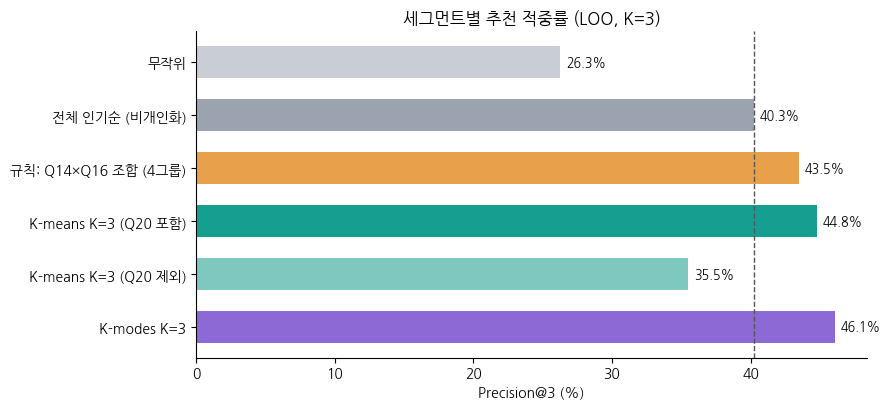


[K=3] 군집별 추천 Top-3 활동
  C0: Q20 야외·자연(55%), Q20 오락·게임(41%), Q20 공연·전시(39%)
  C1: Q20 야외·자연(53%), Q20 오락·게임(45%), Q20 스포츠(43%)
  C2: Q20 공연·전시(56%), Q20 혼자 실내(38%), Q20 공방·DIY(36%)


In [35]:
# 4-4-2. LOO 추천 시뮬레이션: '군집 정보'가 인기순 추천보다 개인 선호를 더 잘 맞히는가
#   각 응답자를 빼고 같은 세그먼트의 Q20 선택률로 Top-N 활동을 추천 → 본인 실제 선택과 비교
#   - Precision@N : 추천 N개 중 본인이 실제 고른 비율
#   - Hit@N       : 추천 N개 중 1개 이상 적중한 비율
#   비교군: 무작위 / 전체 인기순(비개인화) / Q14×Q16 규칙 / K-means(Q20 포함·제외) / K-modes
#   ★ 'Q20 제외 군집'이 인기순보다 높으면 → 군집이 Q20과 독립적으로 취향을 담고 있다는 근거
TOP_N = 3
Y = df_youth[q20_cols].to_numpy().astype(int)
valid = Y.sum(axis=1) > 0
print(f"\nQ20 1개 이상 선택: {valid.sum()}명 / {len(Y)}명 (평가 대상)")


def loo_eval(seg, top_n=TOP_N):
    seg = np.asarray(seg) if seg is not None else np.zeros(len(Y), dtype=int)
    n, glob_sum = len(Y), Y.sum(axis=0)
    hits, precs = [], []
    for i in np.where(valid)[0]:
        g = (glob_sum - Y[i]) / (n - 1)
        mask = seg == seg[i]
        m = mask.sum()
        rate = (Y[mask].sum(axis=0) - Y[i]) / (m - 1) if m > 1 else g
        top = np.argsort(-(rate + 1e-6 * g))[:top_n]   # 동률은 전체 인기순으로
        hits.append(Y[i, top].max())
        precs.append(Y[i, top].mean())
    return np.mean(precs), np.mean(hits)


def random_baseline(top_n=TOP_N):
    s = Y[valid].sum(axis=1)
    m = Y.shape[1]
    return np.mean(s / m), np.mean(1 - comb(m - s, top_n) / comb(m, top_n))


X_noq20, _ = build_matrix(df_youth, culture_cols, use_q20=False)
segmentations = {"전체 인기순 (비개인화)": None,
                 "규칙: Q14×Q16 조합 (4그룹)": combo}
for k in K_LIST:
    segmentations[f"K-means K={k} (Q20 포함)"] = labels_by_k[k]
    segmentations[f"K-means K={k} (Q20 제외)"] = run_kmeans(X_noq20, k)
    segmentations[f"K-modes K={k}"] = method_labels[("K-modes (해밍)", k)]

rand_p, rand_h = random_baseline()
rows = [{"세그먼트": "무작위", f"Precision@{TOP_N}": rand_p, f"Hit@{TOP_N}": rand_h}]
for name, seg in segmentations.items():
    p, h = loo_eval(seg)
    rows.append({"세그먼트": name, f"Precision@{TOP_N}": p, f"Hit@{TOP_N}": h})
rec_eval = pd.DataFrame(rows).set_index("세그먼트")
pop_p = rec_eval.loc["전체 인기순 (비개인화)", f"Precision@{TOP_N}"]
rec_eval["인기순 대비 (%p)"] = (rec_eval[f"Precision@{TOP_N}"] - pop_p) * 100
print(f"\n[4-4-2] LOO 추천 시뮬레이션 (Top-{TOP_N})")
print(rec_eval.round(3).to_string())

# 시각화: K=K_MAIN 중심 비교
plot_rows = ["무작위", "전체 인기순 (비개인화)", "규칙: Q14×Q16 조합 (4그룹)",
             f"K-means K={K_MAIN} (Q20 포함)", f"K-means K={K_MAIN} (Q20 제외)", f"K-modes K={K_MAIN}"]
vals = rec_eval.loc[plot_rows, f"Precision@{TOP_N}"].mul(100)
colors = ["#C9CED6", "#9AA3AF", "#E9A04A", "#159F91", "#7FC8BF", "#8C69D5"]
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(plot_rows[::-1], vals.values[::-1], color=colors[::-1], height=0.6)
ax.axvline(pop_p * 100, color="#555555", linestyle="--", linewidth=1)
for b, v in zip(bars, vals.values[::-1]):
    ax.text(v + 0.4, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel(f"Precision@{TOP_N} (%)")
ax.set_title(f"세그먼트별 추천 적중률 (LOO, K={K_MAIN})", fontsize=12, fontweight="bold")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
save(fig, "4_rec_precision.png")
plt.show()

# 군집별 추천 Top-N이 실제로 서로 다른가
print(f"\n[K={K_MAIN}] 군집별 추천 Top-{TOP_N} 활동")
for g in sorted(np.unique(lab_main)):
    rate = Y[lab_main == g].mean(axis=0)
    top = np.argsort(-rate)[:TOP_N]
    print(f"  C{g}: " + ", ".join(f"{Q20_SHORT[q20_cols[t]]}({rate[t] * 100:.0f}%)" for t in top))

In [36]:
# 판정 요약
k = K_MAIN
abl = ablation.set_index(["변형", "K"])
best_by_sil = method_cmp[method_cmp["K"] == k].set_index("방법")["실루엣(해밍, 공통)"].idxmax()

print("=" * 64)
print(f" 판정 요약 (K = {k}, n = {len(df_youth)})")
print("=" * 64)
print(f"[1] 실루엣 {summary_k.loc[k, '실루엣']:.3f} | 안정성 ARI {summary_k.loc[k, '안정성 ARI']:.3f}"
      f" | 크기 {summary_k.loc[k, '군집 크기']}")
print(f"    실루엣 최고 K = {summary_k['실루엣'].idxmax()}, 안정성 최고 K = {summary_k['안정성 ARI'].idxmax()}")
print(f"[2] 군집 vs Q14×Q16 조합 NMI {combo_match.loc[k, 'NMI(군집 vs 조합)']:.3f}"
      f" | 조합 순도 {combo_match.loc[k, '조합 순도(%)']:.1f}%")
print(f"    depth-2 나무 정확도 {tree_acc.loc[k, 'depth 2']:.3f}"
      f" | Q14·Q16 제외 시 기준 대비 ARI {abl.loc[('Q14·Q16 제외', k), 'ARI(기준 대비)']:.3f}")
print(f"[3] 공통(해밍) 실루엣 최고 방법: {best_by_sil}")
print(f"[4] Precision@{TOP_N}  무작위 {rand_p:.3f} | 인기순 {pop_p:.3f}"
      f" | Q14×Q16 규칙 {rec_eval.loc['규칙: Q14×Q16 조합 (4그룹)', f'Precision@{TOP_N}']:.3f}"
      f" | K-means(Q20 제외) {rec_eval.loc[f'K-means K={k} (Q20 제외)', f'Precision@{TOP_N}']:.3f}")
print("=" * 64)

 판정 요약 (K = 3, n = 154)
[1] 실루엣 0.108 | 안정성 ARI 0.481 | 크기 44 / 49 / 61
    실루엣 최고 K = 2, 안정성 최고 K = 4
[2] 군집 vs Q14×Q16 조합 NMI 0.888 | 조합 순도 80.5%
    depth-2 나무 정확도 1.000 | Q14·Q16 제외 시 기준 대비 ARI 0.013
[3] 공통(해밍) 실루엣 최고 방법: 계층 (해밍·average)
[4] Precision@3  무작위 0.263 | 인기순 0.403 | Q14×Q16 규칙 0.435 | K-means(Q20 제외) 0.355


## 5. 2문항 규칙 기반 3유형

- K-means 군집이 Q14(활동 장소) · Q16(힐링 장소)에 크게 의존함을 확인
- 3개 유형은 유지하면서, 서비스에서 설명 가능한 **2문항 규칙**으로 분류 로직을 단순화

In [37]:
# 2문항 규칙: Q14(활동 장소) → 집안이면 집콕힐링형 / 야외이면 Q16(힐링 장소)로 야외활동형·문화예술형 구분
import sys
sys.path.append("../src")
from culture_classifier import classify_by_rule

TYPE_ORDER = ["집콕힐링형", "야외활동형", "문화예술형"]
df_youth["culture_type"] = df_youth.apply(
    lambda r: classify_by_rule(r["q14_place_pref"], r["q16_healing_spot"]), axis=1)

print("[Q14 × Q16 조합]")
print(pd.crosstab(df_youth["q14_place_pref"], df_youth["q16_healing_spot"]))
print("\n[규칙 기반 유형 분포]")
dist = df_youth["culture_type"].value_counts().reindex(TYPE_ORDER)
print(pd.DataFrame({"인원": dist, "비율(%)": (dist / len(df_youth) * 100).round(1)}))

[Q14 × Q16 조합]
q16_healing_spot  에어컨이 시원하고 세련된 인테리어의 조용한 갤러리나 북카페  피톤치드 가득한 숲속이나 탁 트인 조용한 공원
q14_place_pref                                                               
야외, 집밖                                          30                         49
온라인, 집안                                         31                         44

[규칙 기반 유형 분포]
              인원  비율(%)
culture_type           
집콕힐링형         75   48.7
야외활동형         49   31.8
문화예술형         30   19.5


In [38]:
# 규칙 3유형으로 추천해도 적중률이 유지되는지 (LOO) + 유형별 특징
rule3 = df_youth["culture_type"].to_numpy()
p, h = loo_eval(rule3)
print(f"규칙 3유형 Precision@{TOP_N} {p:.3f} | Hit@{TOP_N} {h:.3f} | 인기순 {pop_p:.3f}")
print(top_lifts(X_base, FEATS, rule3, n=5).to_string())

규칙 3유형 Precision@3 0.431 | Hit@3 0.831 | 인기순 0.403
        n                                                                         두드러진 특징 (전체 대비 %p)
군집                                                                                                  
문화예술형  30  Q16 힐링장소: 갤러리·북카페 +60, Q14 장소: 야외 +49, Q19 자극: 해석형 +24, Q15 소통: 가벼운 대화 +22, Q20 공연·전시 +16
야외활동형  49               Q14 장소: 야외 +49, Q16 힐링장소: 숲·공원 +40, Q20 스포츠 +15, Q20 야외·자연 +12, Q20 오락·게임 +9
집콕힐링형  75         Q14 장소: 집안 +51, Q15 소통: 혼자 집중 +10, Q19 자극: 감각형 +6, Q15 소통: 조용히 함께 +4, Q20 혼자 실내 +4


## 6. 유형별 Q20 문화 활동 선호 차이

- 유형 vs 나머지 Fisher 정확검정 + BH-FDR 보정으로 유의한 차이만 해석
- 유의한 활동이 일부에 그쳐, 3유형은 **정밀한 선호 예측이 아닌 추천 후보의 우선순위 기준**으로 활용

In [39]:
# 유형별 Q20 문화 활동 선호 특성
#   ① 유형별 활동 선호율 (%)    = 유형 내 선택 인원 ÷ 유형 인원 × 100
#   ② 전체 대비 선호율 차이 (%p) = 유형별 선호율 − 전체 청년층 선호율
#   ③ 유형별 대표 활동 TOP 3     = 선호율 순 / 차이(%p) 순
#   + 유형 vs 나머지 Fisher 정확검정 (BH-FDR 보정) → 작은 차이 과대해석 방지
pd.set_option("display.unicode.east_asian_width", True)

Q20_LABEL = {
    "q20_craft": "공방·DIY",     "q20_concert": "공연·전시",   "q20_outdoor": "야외·자연",
    "q20_cafe": "혼자 실내",      "q20_heritage": "역사·전통",  "q20_sport": "스포츠",
    "q20_fun": "오락·게임",       "q20_modern": "현대미술",     "q20_classic": "클래식",
}
OUT_DIR = "../outputs/segment_q20"
os.makedirs(OUT_DIR, exist_ok=True)

seg = df_youth["culture_type"]
Y = df_youth[q20_cols].astype(int)
n_all = len(df_youth)
n_type = seg.value_counts().reindex(TYPE_ORDER)
print(f"[유형 인원] 전체 {n_all}명 | " + " | ".join(f"{t} {n}명" for t, n in n_type.items()))
print(f"Q20 미응답(0개 선택): {(Y.sum(axis=1) == 0).sum()}명 → 분모에는 포함")

[유형 인원] 전체 154명 | 집콕힐링형 75명 | 야외활동형 49명 | 문화예술형 30명
Q20 미응답(0개 선택): 0명 → 분모에는 포함


In [40]:
# ---------- ① 유형별 활동 선호율 ----------
count = Y.groupby(seg).sum().T.reindex(columns=TYPE_ORDER)       # 선택 인원
count.insert(0, "전체", Y.sum())
denom = pd.Series({"전체": n_all, **n_type.to_dict()})
rate = count.div(denom, axis=1).mul(100)                          # 선호율(%)
rate.index = count.index = [Q20_LABEL[c] for c in q20_cols]

# 장표용 표: "41.3% (31/75)"
col_names = {"전체": f"전체 {n_all}명", **{t: f"{t} {n_type[t]}명" for t in TYPE_ORDER}}
table_rate = pd.DataFrame({
    col_names[c]: [f"{r:.1f}% ({int(k)}/{int(denom[c])})" for r, k in zip(rate[c], count[c])]
    for c in rate.columns
}, index=rate.index)
table_rate = table_rate.loc[rate["전체"].sort_values(ascending=False).index]  # 전체 인기순 정렬
print("[① 유형별 Q20 활동 선호율]  ※ 복수선택이라 열 합계 100% 초과 정상")
print(table_rate.to_string(), "\n")

[① 유형별 Q20 활동 선호율]  ※ 복수선택이라 열 합계 100% 초과 정상
               전체 154명 집콕힐링형 75명 야외활동형 49명 문화예술형 30명
공연·전시  43.5% (67/154)   44.0% (33/75)   32.7% (16/49)   60.0% (18/30)
야외·자연  41.6% (64/154)   37.3% (28/75)   53.1% (26/49)   33.3% (10/30)
오락·게임  35.7% (55/154)   37.3% (28/75)   44.9% (22/49)    16.7% (5/30)
공방·DIY   27.9% (43/154)   30.7% (23/75)   22.4% (11/49)    30.0% (9/30)
혼자 실내  27.9% (43/154)   32.0% (24/75)    12.2% (6/49)   43.3% (13/30)
스포츠     27.9% (43/154)   17.3% (13/75)   42.9% (21/49)    30.0% (9/30)
역사·전통  13.6% (21/154)   13.3% (10/75)     8.2% (4/49)    23.3% (7/30)
현대미술   11.0% (17/154)     9.3% (7/75)     8.2% (4/49)    20.0% (6/30)
클래식      7.1% (11/154)     6.7% (5/75)     6.1% (3/49)    10.0% (3/30) 



In [41]:
# ---------- ② 전체 대비 선호율 차이 + 유의성 ----------
diff = rate[TYPE_ORDER].sub(rate["전체"], axis=0)                 # %p

# 유형 vs 나머지 2×2 Fisher 정확검정 (소표본에 적합), 27개 검정 BH-FDR 보정
pvals = pd.DataFrame(index=diff.index, columns=TYPE_ORDER, dtype=float)
for col, label in zip(q20_cols, diff.index):
    for t in TYPE_ORDER:
        in_t = seg.eq(t)
        a, b = Y.loc[in_t, col].sum(), in_t.sum() - Y.loc[in_t, col].sum()
        c, d = Y.loc[~in_t, col].sum(), (~in_t).sum() - Y.loc[~in_t, col].sum()
        pvals.loc[label, t] = fisher_exact([[a, b], [c, d]])[1]
qvals = pd.DataFrame(bh_fdr(pvals.values.ravel()).reshape(pvals.shape),
                     index=pvals.index, columns=pvals.columns)

def star(q):
    return "**" if q < 0.05 else ("*" if q < 0.10 else "")

table_diff = pd.DataFrame({
    t: [f"{d:+.1f}%p{star(q)}" for d, q in zip(diff[t], qvals[t])] for t in TYPE_ORDER
}, index=diff.index).loc[table_rate.index]
print("[② 전체 대비 선호율 차이]  ** q<0.05, * q<0.10 (유형 vs 나머지 Fisher, FDR 보정)")
print(table_diff.to_string(), "\n")

# 활동별로 세 유형 간 차이가 있는지 (3×2 카이제곱, FDR 보정)
omni = []
for col, label in zip(q20_cols, diff.index):
    ct = pd.crosstab(seg, Y[col]).reindex(TYPE_ORDER)
    chi2, p, _, exp = chi2_contingency(ct)
    omni.append({"활동": label, "카이제곱 p": p, "최소 기대빈도": exp.min()})
omni = pd.DataFrame(omni).set_index("활동")
omni["q(FDR)"] = bh_fdr(omni["카이제곱 p"])
omni["유형 간 차이"] = np.where(omni["q(FDR)"] < 0.05, "있음", np.where(omni["q(FDR)"] < 0.10, "경향", "-"))
print("[참고] 활동별 세 유형 간 차이 검정")
print(omni.loc[table_rate.index].round(3).to_string(), "\n")

[② 전체 대비 선호율 차이]  ** q<0.05, * q<0.10 (유형 vs 나머지 Fisher, FDR 보정)
          집콕힐링형 야외활동형 문화예술형
공연·전시     +0.5%p    -10.9%p    +16.5%p
야외·자연     -4.2%p    +11.5%p     -8.2%p
오락·게임     +1.6%p     +9.2%p    -19.0%p
공방·DIY      +2.7%p     -5.5%p     +2.1%p
혼자 실내     +4.1%p   -15.7%p*    +15.4%p
스포츠      -10.6%p*   +14.9%p*     +2.1%p
역사·전통     -0.3%p     -5.5%p     +9.7%p
현대미술      -1.7%p     -2.9%p     +9.0%p
클래식        -0.5%p     -1.0%p     +2.9%p 

[참고] 활동별 세 유형 간 차이 검정
           카이제곱 p  최소 기대빈도  q(FDR) 유형 간 차이
공연·전시       0.059         13.052   0.132            -
야외·자연       0.132         12.468   0.237            -
오락·게임       0.036         10.714   0.109            -
공방·DIY        0.584          8.377   0.657            -
혼자 실내       0.006          8.377   0.036         있음
스포츠          0.008          8.377   0.036         있음
역사·전통       0.161          4.091   0.242            -
현대미술        0.214          3.312   0.275            -
클래식          0.790          2.143   0.790            -

In [42]:
# ---------- ③ 유형별 대표 활동 TOP 3 ----------
#   - 선호율 순: 그 유형이 실제로 많이 고르는 활동 (추천 후보)
#   - 차이 순  : 다른 유형과 구분되는 활동 (유형 설명·네이밍용)
rows = []
for t in TYPE_ORDER:
    by_rate = rate[t].sort_values(ascending=False).head(3)
    by_diff = diff[t].sort_values(ascending=False).head(3)
    rows.append({
        "유형": f"{t} ({n_type[t]}명)",
        "TOP3 · 선호율 순": " / ".join(f"{a} {v:.0f}%" for a, v in by_rate.items()),
        "TOP3 · 전체 대비 차이 순": " / ".join(
            f"{a} {v:+.0f}%p{star(qvals.loc[a, t])}" for a, v in by_diff.items()),
    })
top3 = pd.DataFrame(rows).set_index("유형")
print("[③ 유형별 대표 활동 TOP 3]")
print(top3.to_string(), "\n")

[③ 유형별 대표 활동 TOP 3]
                                                TOP3 · 선호율 순                             TOP3 · 전체 대비 차이 순
유형                                                                                                                 
집콕힐링형 (75명)  공연·전시 44% / 오락·게임 37% / 야외·자연 37%      혼자 실내 +4%p / 공방·DIY +3%p / 오락·게임 +2%p
야외활동형 (49명)     야외·자연 53% / 오락·게임 45% / 스포츠 43%     스포츠 +15%p* / 야외·자연 +12%p / 오락·게임 +9%p
문화예술형 (30명)  공연·전시 60% / 혼자 실내 43% / 야외·자연 33%  공연·전시 +16%p / 혼자 실내 +15%p / 역사·전통 +10%p 



In [43]:
# ---------- 결과 해석 가이드 ----------
n_sig_act = (omni["q(FDR)"] < 0.05).sum()
n_sig_cell = (qvals < 0.05).sum().sum()
max_gap = (rate[TYPE_ORDER].max(axis=1) - rate[TYPE_ORDER].min(axis=1))
print("=" * 70)
print(f" 세 유형 간 차이가 유의한 활동: {n_sig_act}/9개 | 전체 대비 유의한 차이: {n_sig_cell}/27칸")
print(f" 유형 간 선호율 최대 격차: {max_gap.idxmax()} {max_gap.max():.1f}%p | 평균 격차 {max_gap.mean():.1f}%p")
if n_sig_act >= 3:
    print(" → 2문항 규칙 유형 사이에 Q20 문화 취향 차이가 뚜렷함: 유형별 대표 활동으로 설명 가능")
elif n_sig_act >= 1:
    print(" → 일부 활동에서만 차이: 유형 설명은 유의한 활동 위주로, 추천은 개인 Q20 응답을 함께 반영 권장")
else:
    print(" → 유형 간 Q20 차이가 약함: 유형만으로 활동 선호를 구분한다고 보기 어려움, 개인 Q20 반영 필요")
print(f" ※ 문화예술형 {n_type['문화예술형']}명: 1명 차이가 {100 / n_type['문화예술형']:.1f}%p → 10%p 미만 차이는 '경향'으로만 해석")
print("=" * 70)

 세 유형 간 차이가 유의한 활동: 2/9개 | 전체 대비 유의한 차이: 0/27칸
 유형 간 선호율 최대 격차: 혼자 실내 31.1%p | 평균 격차 19.0%p
 → 일부 활동에서만 차이: 유형 설명은 유의한 활동 위주로, 추천은 개인 Q20 응답을 함께 반영 권장
 ※ 문화예술형 30명: 1명 차이가 3.3%p → 10%p 미만 차이는 '경향'으로만 해석


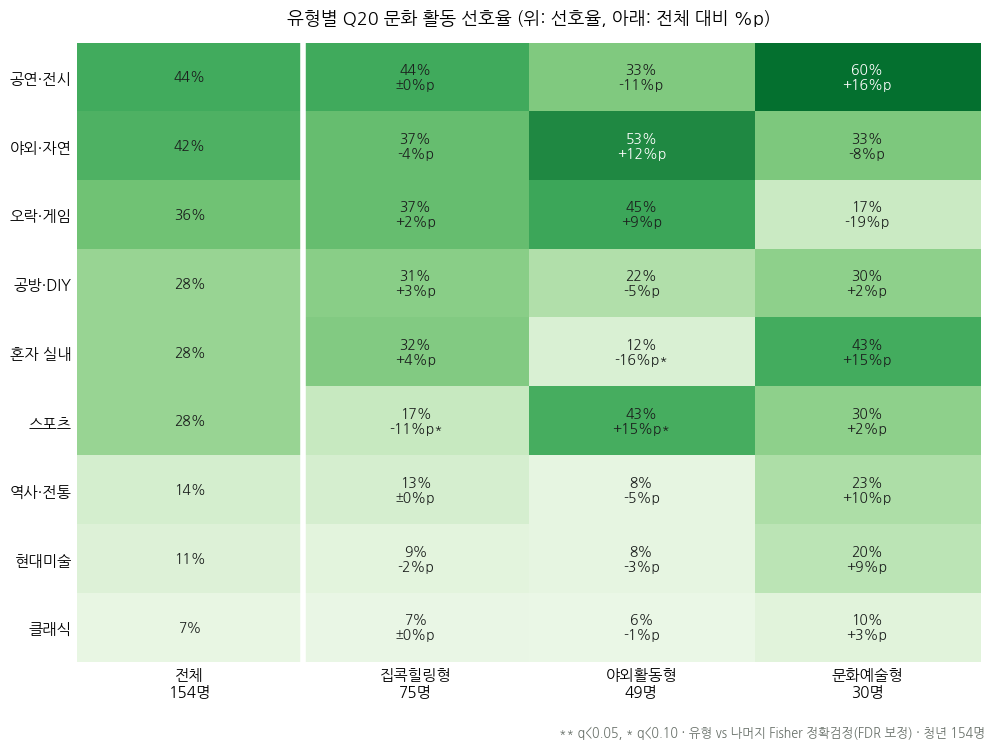

In [44]:
# ---------- 시각화: 선호율 히트맵 + 차이 표시 (장표용) ----------
order = table_rate.index
cols = ["전체"] + TYPE_ORDER
vals = rate.loc[order, cols].values

fig, ax = plt.subplots(figsize=(10, 7.2))
ax.imshow(vals, cmap="Greens", vmin=0, vmax=max(70, np.ceil(vals.max() / 10) * 10), aspect="auto")
for i, act in enumerate(order):
    for j, c in enumerate(cols):
        v = rate.loc[act, c]
        txt = f"{v:.0f}%"
        if c != "전체":
            d, q = diff.loc[act, c], qvals.loc[act, c]
            txt += ("\n±0%p" if round(d) == 0 else f"\n{d:+.0f}%p") + star(q)
        ax.text(j, i, txt, ha="center", va="center", fontsize=10,
                fontweight="bold" if (c != "전체" and qvals.loc[act, c] < 0.10) else "normal",
                color="white" if v >= 45 else "#1B1F1D")
ax.set_xticks(range(len(cols)))
ax.set_xticklabels([col_names[c].replace(" ", "\n", 1) for c in cols], fontsize=11)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=11)
ax.axvline(0.5, color="white", linewidth=4)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("유형별 Q20 문화 활동 선호율 (위: 선호율, 아래: 전체 대비 %p)",
             fontsize=13, fontweight="bold", pad=14)
fig.text(0.99, -0.03, "** q<0.05, * q<0.10 · 유형 vs 나머지 Fisher 정확검정(FDR 보정) · 청년 154명",
         ha="right", fontsize=9, color="#687069")
plt.tight_layout()
fig.savefig(f"{IMG_DIR}/q20_segment_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

In [45]:
# ---------- 저장 (엑셀에서 바로 열리도록 utf-8-sig) ----------
rate.loc[order].round(1).to_csv(os.path.join(OUT_DIR, "q20_rate.csv"), encoding="utf-8-sig")
diff.loc[order].round(1).to_csv(os.path.join(OUT_DIR, "q20_diff_pp.csv"), encoding="utf-8-sig")
qvals.loc[order].round(4).to_csv(os.path.join(OUT_DIR, "q20_diff_qvalue.csv"), encoding="utf-8-sig")
top3.to_csv(os.path.join(OUT_DIR, "q20_top3.csv"), encoding="utf-8-sig")
print(f"[저장] {OUT_DIR}/ (CSV 4개)")

[저장] ../outputs/segment_q20/ (CSV 4개)
